IMPORTS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import RandomizedSearchCV

from xgboost import XGBRegressor

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings 
warnings.filterwarnings('ignore')
print("All libraries imported successfully!")

All libraries imported successfully!


Dataset

In [2]:
df = pd.read_csv("student_performance_prediction_dataset_with_previous_grades.csv")

In [3]:
df.head()

,student_id,age,gender,study_hours,attendance,sleep_hours,previous_grade,assignments_completed,practice_tests_taken,group_study_hours,...,social_media_hours,family_income,parent_education,internet_access,device_type,school_type,extracurriculars,final_grade,grade_category,pass_fail
0,1,21,Male,1.645404,79.154521,8.230886,96.053840,7.719620,1.871170,1.447894,...,4.018412,Medium,Master,Yes,Mobile,Private,Coding Club,59.248749,D,Pass
1,2,18,Male,4.462126,72.526685,6.139219,53.024821,6.754758,5.630071,1.891288,...,3.268642,Medium,Master,Yes,Laptop,Public,NaN,58.595595,D,Pass
2,3,19,Female,6.220212,98.531716,6.946313,78.775422,10.000000,7.862877,1.774356,...,2.327293,Low,High School,Yes,Tablet,Private,Music,85.855289,A,Pass
3,4,21,Female,1.826644,97.731245,8.297048,76.122618,7.440486,2.316252,1.204271,...,1.163367,Medium,Bachelor,Yes,Laptop,Public,Debate,42.117503,F,Fail
4,5,17,Male,3.789322,78.589107,6.777171,81.305681,9.962609,5.335697,1.399230,...,0.411183,High,High School,Yes,Laptop,Private,Debate,62.870474,C,Pass


EDA

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 25 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   student_id             300000 non-null  int64  
 1   age                    300000 non-null  int64  
 2   gender                 300000 non-null  str    
 3   study_hours            300000 non-null  float64
 4   attendance             300000 non-null  float64
 5   sleep_hours            300000 non-null  float64
 6   previous_grade         300000 non-null  float64
 7   assignments_completed  300000 non-null  float64
 8   practice_tests_taken   300000 non-null  float64
 9   group_study_hours      300000 non-null  float64
 10  notes_quality_score    300000 non-null  float64
 11  time_management_score  300000 non-null  float64
 12  motivation_level       300000 non-null  float64
 13  mental_health_score    300000 non-null  float64
 14  screen_time            300000 non-null  float64

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
student_id,300000.0,150000.500000,86602.684716,1.0,75000.750000,150000.500000,225000.250000,300000.000000
age,300000.0,17.999070,1.999235,15.0,16.000000,18.000000,20.000000,21.000000
study_hours,300000.0,4.503062,1.978513,0.0,3.143566,4.498272,5.843646,12.000000
attendance,300000.0,84.699395,9.419450,40.0,78.241008,84.990371,91.732244,100.000000
sleep_hours,300000.0,6.991431,1.463070,3.0,5.992666,6.999011,8.013284,10.000000
previous_grade,300000.0,69.840184,14.683157,20.0,59.870863,69.955736,80.102857,100.000000
assignments_completed,300000.0,7.836044,1.732474,0.0,6.654817,8.000829,9.357154,10.000000
practice_tests_taken,300000.0,4.017508,1.956444,0.0,2.655243,4.001981,5.349494,10.000000
group_study_hours,300000.0,1.529057,0.941525,0.0,0.826462,1.499206,2.172680,5.840593
notes_quality_score,300000.0,6.946017,1.885193,1.0,5.653740,7.011212,8.356150,10.000000


In [6]:
df.isnull().sum()

student_id                   0
age                          0
gender                       0
study_hours                  0
attendance                   0
sleep_hours                  0
previous_grade               0
assignments_completed        0
practice_tests_taken         0
group_study_hours            0
notes_quality_score          0
time_management_score        0
motivation_level             0
mental_health_score          0
screen_time                  0
social_media_hours           0
family_income                0
parent_education             0
internet_access              0
device_type              15105
school_type                  0
extracurriculars         49981
final_grade                  0
grade_category               4
pass_fail                    0
dtype: int64

EDA

In [7]:
df = df.drop(columns=['student_id'])

In [8]:
df['extracurriculars'] = df['extracurriculars'].fillna('Unknown')
df['device_type'] = df['device_type'].fillna('Unknown')

In [9]:
df['final_grade'].describe()
df['previous_grade'].describe()

df['grade_category'].value_counts(dropna=False)
df['pass_fail'].value_counts(dropna=False)

pass_fail
Pass    180729
Fail    119271
Name: count, dtype: int64

In [10]:
pd.crosstab(df['grade_category'], df['pass_fail'])

pass_fail,Fail,Pass
grade_category,,
A,0,3593
A+,0,297
B,0,20910
C,0,61495
D,0,94434
F,119267,0


In [11]:
df.groupby('grade_category')['final_grade'].agg(['count', 'min', 'max', 'mean'])

,count,min,max,mean
grade_category,,,,
A,3593,80.000590,89.998706,83.321732
A+,297,90.011045,100.000000,93.087820
B,20910,70.000594,79.998993,73.825943
C,61495,60.000018,69.999887,64.354244
D,94434,50.000043,59.999990,54.894852
F,119267,0.670384,49.999993,41.206995


In [12]:
print("Shape:", df.shape)

print("\nDuplicates:", df.duplicated().sum())

print("\nGrade Category:")
print(df['grade_category'].value_counts(dropna=False))

print("\nPass/Fail:")
print(df['pass_fail'].value_counts(dropna=False))

print("\nGrade Category vs Pass/Fail:")
print(pd.crosstab(df['grade_category'], df['pass_fail'], dropna=False))

print("\nFinal Grade by Category:")
print(df.groupby('grade_category', dropna=False)['final_grade'].agg(
    ['count', 'min', 'max', 'mean', 'std']
))

Shape: (300000, 24)

Duplicates: 0

Grade Category:
grade_category
F      119267
D       94434
C       61495
B       20910
A        3593
A+        297
NaN         4
Name: count, dtype: int64

Pass/Fail:
pass_fail
Pass    180729
Fail    119271
Name: count, dtype: int64

Grade Category vs Pass/Fail:
pass_fail         Fail   Pass
grade_category               
A                    0   3593
A+                   0    297
B                    0  20910
C                    0  61495
D                    0  94434
F               119267      0
NaN                  4      0

Final Grade by Category:
                 count        min         max       mean       std
grade_category                                                    
A                 3593  80.000590   89.998706  83.321732  2.550712
A+                 297  90.011045  100.000000  93.087820  2.623818
B                20910  70.000594   79.998993  73.825943  2.697424
C                61495  60.000018   69.999887  64.354244  2.809850
D  

In [13]:
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 24 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   age                    300000 non-null  int64  
 1   gender                 300000 non-null  str    
 2   study_hours            300000 non-null  float64
 3   attendance             300000 non-null  float64
 4   sleep_hours            300000 non-null  float64
 5   previous_grade         300000 non-null  float64
 6   assignments_completed  300000 non-null  float64
 7   practice_tests_taken   300000 non-null  float64
 8   group_study_hours      300000 non-null  float64
 9   notes_quality_score    300000 non-null  float64
 10  time_management_score  300000 non-null  float64
 11  motivation_level       300000 non-null  float64
 12  mental_health_score    300000 non-null  float64
 13  screen_time            300000 non-null  float64
 14  social_media_hours     300000 non-null  float64

In [14]:
df.isnull().sum()

age                      0
gender                   0
study_hours              0
attendance               0
sleep_hours              0
previous_grade           0
assignments_completed    0
practice_tests_taken     0
group_study_hours        0
notes_quality_score      0
time_management_score    0
motivation_level         0
mental_health_score      0
screen_time              0
social_media_hours       0
family_income            0
parent_education         0
internet_access          0
device_type              0
school_type              0
extracurriculars         0
final_grade              0
grade_category           4
pass_fail                0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.select_dtypes(include='number').columns

Index(['age', 'study_hours', 'attendance', 'sleep_hours', 'previous_grade',
       'assignments_completed', 'practice_tests_taken', 'group_study_hours',
       'notes_quality_score', 'time_management_score', 'motivation_level',
       'mental_health_score', 'screen_time', 'social_media_hours',
       'final_grade'],
      dtype='str')

In [17]:
df.select_dtypes(include='object').columns

Index(['gender', 'family_income', 'parent_education', 'internet_access',
       'device_type', 'school_type', 'extracurriculars', 'grade_category',
       'pass_fail'],
      dtype='str')

In [18]:
df['final_grade'].describe()

count    300000.000000
mean         53.089206
std          12.225161
min           0.000000
25%          44.867737
50%          53.167495
75%          61.379373
max         100.000000
Name: final_grade, dtype: float64

VISUALIZATION

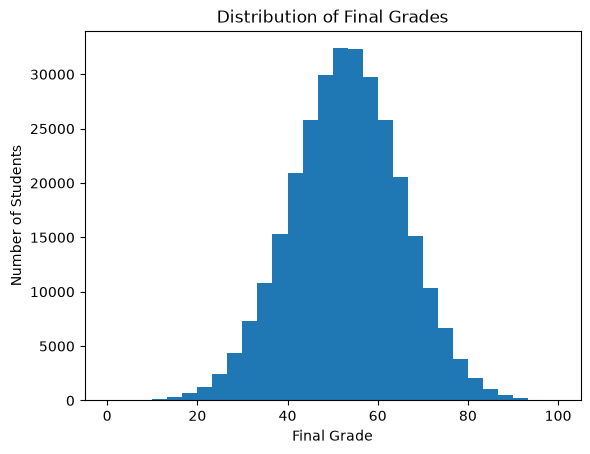

In [19]:
plt.hist(df['final_grade'], bins=30)
plt.xlabel('Final Grade')
plt.ylabel('Number of Students')
plt.title('Distribution of Final Grades')
plt.show()

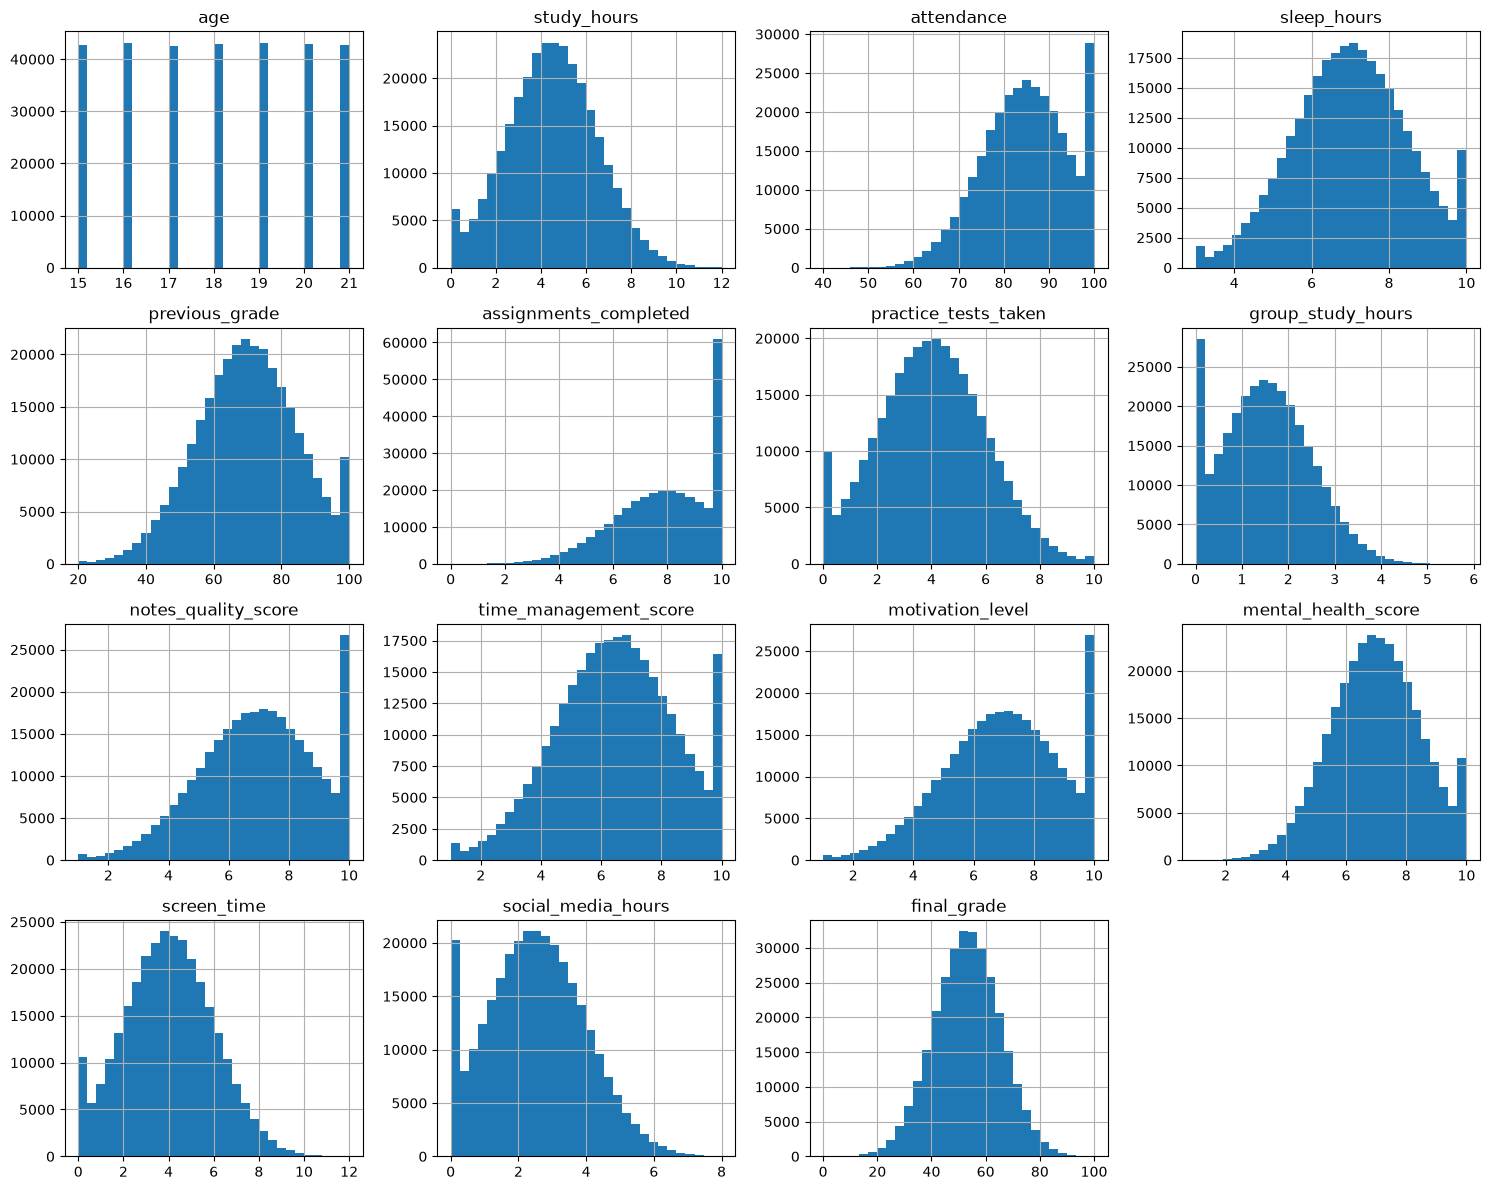

In [20]:
df.select_dtypes(include='number').hist(figsize=(15, 12), bins=30)
plt.tight_layout()
plt.show()

In [21]:
for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


gender:
gender
Female    144083
Male      143871
Other      12046
Name: count, dtype: int64

family_income:
family_income
Medium    134859
Low       105067
High       60074
Name: count, dtype: int64

parent_education:
parent_education
High School    135098
Bachelor       105227
Master          44939
PhD             14736
Name: count, dtype: int64

internet_access:
internet_access
Yes    254951
No      45049
Name: count, dtype: int64

device_type:
device_type
Laptop     164893
Mobile      90116
Tablet      29886
Unknown     15105
Name: count, dtype: int64

school_type:
school_type
Public     195174
Private    104826
Name: count, dtype: int64

extracurriculars:
extracurriculars
Arts           50235
Coding Club    50187
Music          50097
Unknown        49981
Sports         49797
Debate         49703
Name: count, dtype: int64

grade_category:
grade_category
F     119267
D      94434
C      61495
B      20910
A       3593
A+       297
Name: count, dtype: int64

pass_fail:
pass_fail
Pass

In [22]:
df.groupby('gender')['final_grade'].mean()

gender
Female    53.089439
Male      53.089574
Other     53.082033
Name: final_grade, dtype: float64

In [23]:
df.groupby('family_income')['final_grade'].mean()

family_income
High      53.121152
Low       53.113228
Medium    53.056261
Name: final_grade, dtype: float64

In [24]:
df.groupby('parent_education')['final_grade'].mean()

parent_education
Bachelor       53.047053
High School    53.134791
Master         53.099186
PhD            52.941863
Name: final_grade, dtype: float64

In [25]:
df.groupby('internet_access')['final_grade'].mean()

internet_access
No     53.087985
Yes    53.089422
Name: final_grade, dtype: float64

In [26]:
df.groupby('device_type')['final_grade'].mean()

device_type
Laptop     53.106860
Mobile     53.091675
Tablet     53.029411
Unknown    53.000073
Name: final_grade, dtype: float64

In [27]:
df.groupby('school_type')['final_grade'].mean()

school_type
Private    53.076770
Public     53.095886
Name: final_grade, dtype: float64

In [28]:
df.groupby('extracurriculars')['final_grade'].mean()

extracurriculars
Arts           53.081873
Coding Club    53.100124
Debate         53.063236
Music          53.197425
Sports         52.957652
Unknown        53.134040
Name: final_grade, dtype: float64

In [29]:
df.groupby('grade_category')['final_grade'].agg(['mean', 'min', 'max'])

,mean,min,max
grade_category,,,
A,83.321732,80.000590,89.998706
A+,93.087820,90.011045,100.000000
B,73.825943,70.000594,79.998993
C,64.354244,60.000018,69.999887
D,54.894852,50.000043,59.999990
F,41.206995,0.670384,49.999993


In [30]:
df.groupby('pass_fail')['final_grade'].agg(['mean', 'min', 'max'])

,mean,min,max
pass_fail,,,
Fail,41.205613,0.000000,49.999993
Pass,60.931711,50.000043,100.000000


In [31]:
df.select_dtypes(include='number').corr()['final_grade'].sort_values(ascending=False)

final_grade              1.000000
study_hours              0.430957
previous_grade           0.393373
time_management_score    0.312778
motivation_level         0.306361
assignments_completed    0.282054
practice_tests_taken     0.213146
attendance               0.204748
notes_quality_score      0.201487
mental_health_score      0.159313
sleep_hours              0.122948
group_study_hours        0.075739
age                     -0.000644
social_media_hours      -0.157292
screen_time             -0.157975
Name: final_grade, dtype: float64

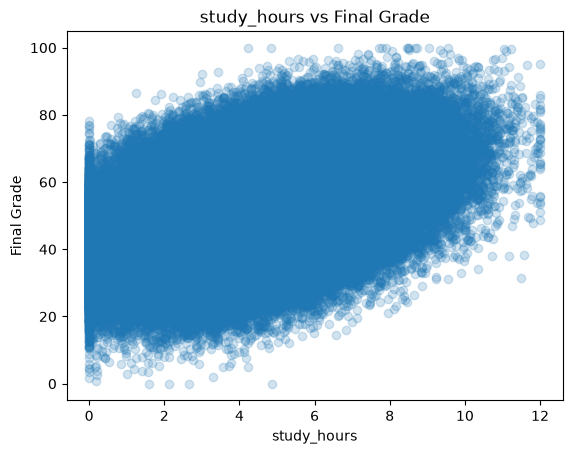

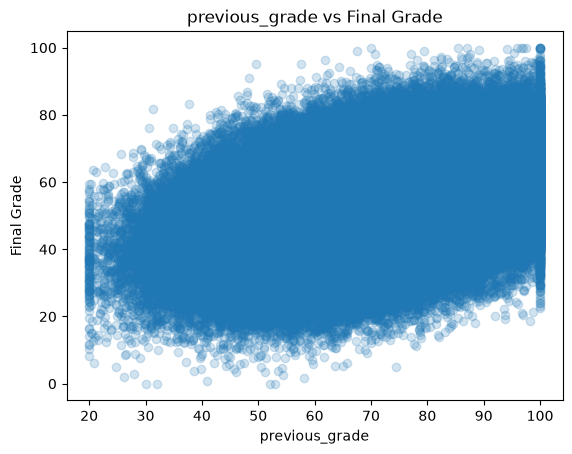

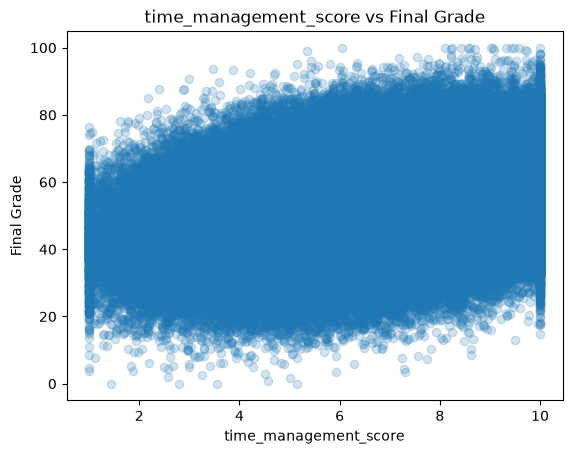

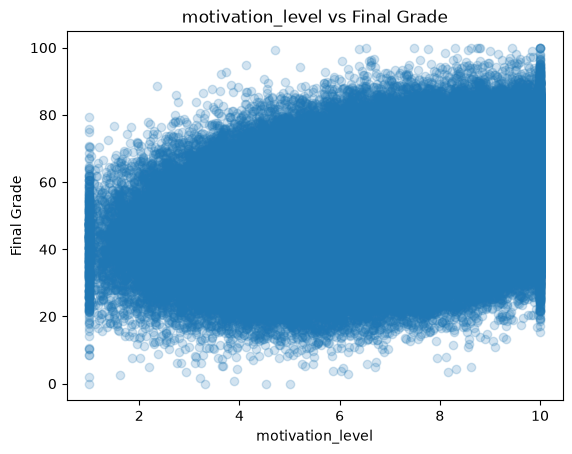

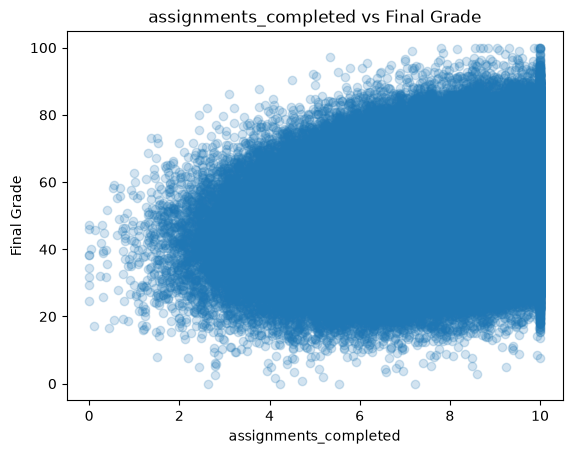

In [32]:
top_features = ['study_hours', 'previous_grade', 'time_management_score',
                'motivation_level', 'assignments_completed']

for col in top_features:
    plt.scatter(df[col], df['final_grade'], alpha=0.2)
    plt.xlabel(col)
    plt.ylabel('Final Grade')
    plt.title(f'{col} vs Final Grade')
    plt.show()

In [33]:
for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


gender:
gender
Female    144083
Male      143871
Other      12046
Name: count, dtype: int64

family_income:
family_income
Medium    134859
Low       105067
High       60074
Name: count, dtype: int64

parent_education:
parent_education
High School    135098
Bachelor       105227
Master          44939
PhD             14736
Name: count, dtype: int64

internet_access:
internet_access
Yes    254951
No      45049
Name: count, dtype: int64

device_type:
device_type
Laptop     164893
Mobile      90116
Tablet      29886
Unknown     15105
Name: count, dtype: int64

school_type:
school_type
Public     195174
Private    104826
Name: count, dtype: int64

extracurriculars:
extracurriculars
Arts           50235
Coding Club    50187
Music          50097
Unknown        49981
Sports         49797
Debate         49703
Name: count, dtype: int64

grade_category:
grade_category
F     119267
D      94434
C      61495
B      20910
A       3593
A+       297
Name: count, dtype: int64

pass_fail:
pass_fail
Pass

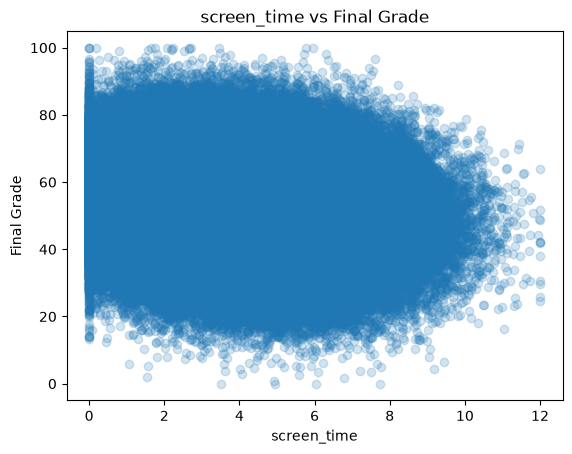

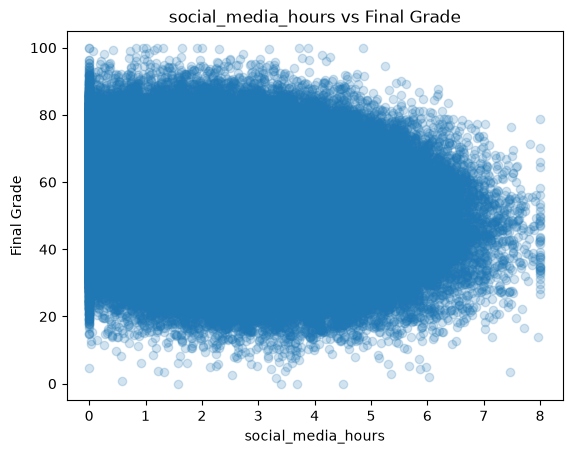

In [34]:
for col in ['screen_time', 'social_media_hours']:
    plt.scatter(df[col], df['final_grade'], alpha=0.2)
    plt.xlabel(col)
    plt.ylabel('Final Grade')
    plt.title(f'{col} vs Final Grade')
    plt.show()

In [35]:
df.select_dtypes(include='number').corr()

,age,study_hours,attendance,sleep_hours,previous_grade,assignments_completed,practice_tests_taken,group_study_hours,notes_quality_score,time_management_score,motivation_level,mental_health_score,screen_time,social_media_hours,final_grade
age,1.000000,0.001834,-0.001181,-0.002117,-0.003490,-0.001813,-0.001914,0.000412,0.000385,0.000650,-0.000037,-0.001233,-0.001300,-0.002011,-0.000644
study_hours,0.001834,1.000000,0.000081,0.000072,-0.001439,0.002761,-0.000521,0.000828,-0.000472,0.003418,0.004853,0.003882,0.001149,-0.003675,0.430957
attendance,-0.001181,0.000081,1.000000,0.003093,-0.002521,0.002966,-0.001324,0.001038,-0.001321,0.001340,0.001535,0.001938,-0.000720,-0.001397,0.204748
sleep_hours,-0.002117,0.000072,0.003093,1.000000,0.002499,0.000481,-0.000246,0.000378,0.000890,0.001608,0.003246,0.000598,-0.003066,-0.000479,0.122948
previous_grade,-0.003490,-0.001439,-0.002521,0.002499,1.000000,0.000127,0.001459,0.002410,-0.002766,-0.001798,-0.002177,-0.002127,0.000829,-0.001311,0.393373
assignments_completed,-0.001813,0.002761,0.002966,0.000481,0.000127,1.000000,-0.001008,-0.000972,0.002062,-0.001478,-0.000514,-0.000429,-0.003476,0.001875,0.282054
practice_tests_taken,-0.001914,-0.000521,-0.001324,-0.000246,0.001459,-0.001008,1.000000,0.001929,-0.001094,0.002055,0.000668,0.003624,-0.001505,-0.000767,0.213146
group_study_hours,0.000412,0.000828,0.001038,0.000378,0.002410,-0.000972,0.001929,1.000000,0.001872,-0.004149,0.002065,-0.002005,0.000029,0.001649,0.075739
notes_quality_score,0.000385,-0.000472,-0.001321,0.000890,-0.002766,0.002062,-0.001094,0.001872,1.000000,-0.001571,-0.000013,-0.001543,0.001907,0.000022,0.201487
time_management_score,0.000650,0.003418,0.001340,0.001608,-0.001798,-0.001478,0.002055,-0.004149,-0.001571,1.000000,0.000184,0.001107,0.001223,-0.000562,0.312778


CORRELATION VISUALIZATION

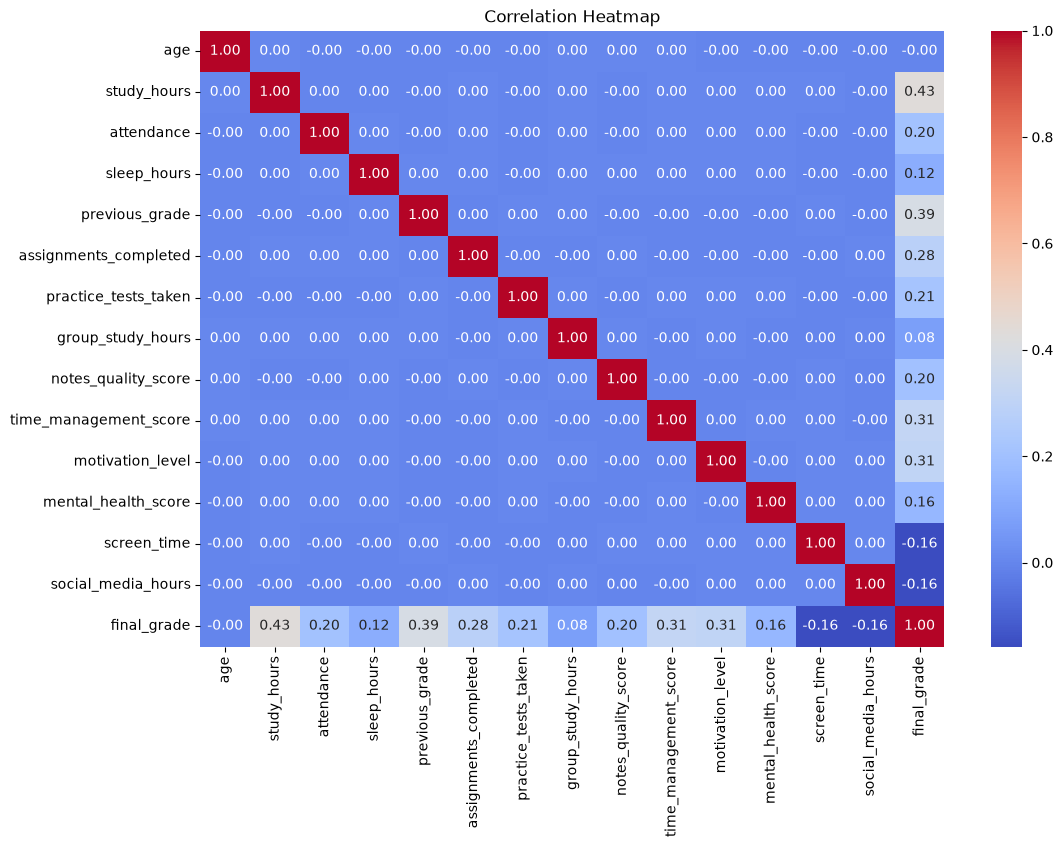

In [36]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap')
plt.show()

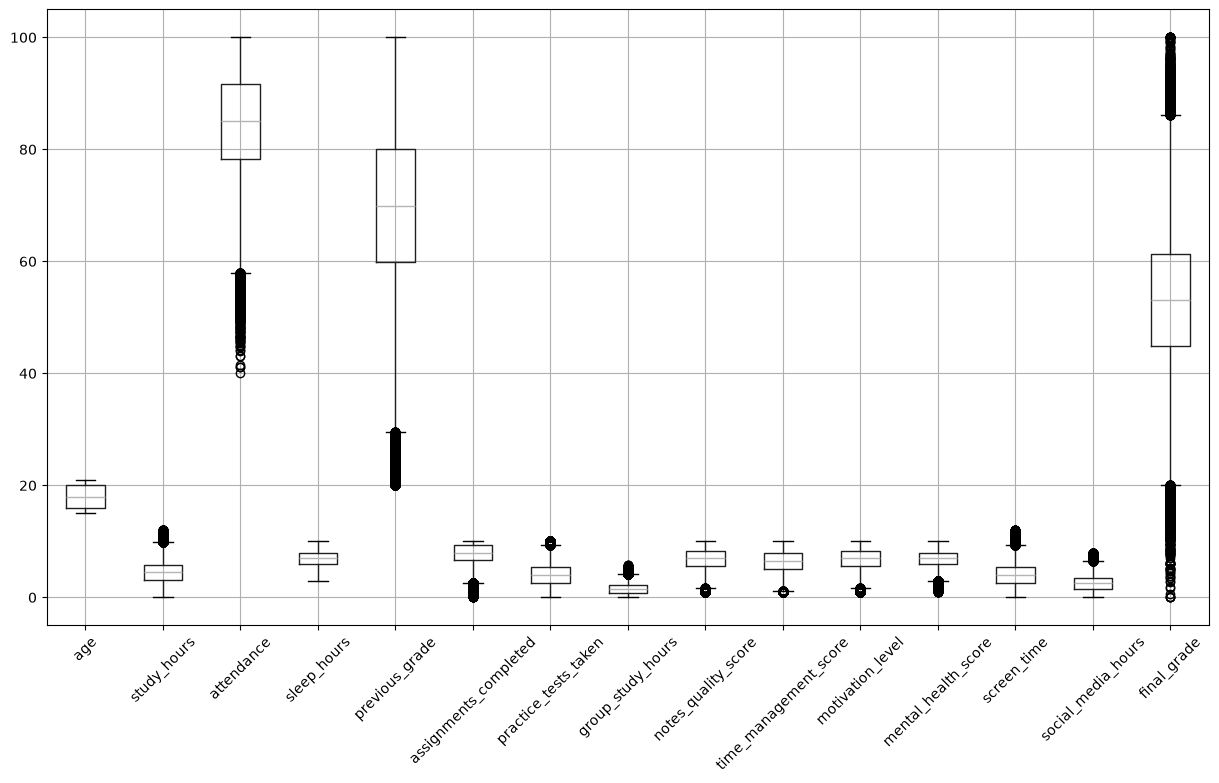

In [37]:
df.select_dtypes(include='number').boxplot(figsize=(15, 8))
plt.xticks(rotation=45)
plt.show()

In [38]:
df.select_dtypes(include='number').agg(['min', 'max']).T

,min,max
age,15.0,21.000000
study_hours,0.0,12.000000
attendance,40.0,100.000000
sleep_hours,3.0,10.000000
previous_grade,20.0,100.000000
assignments_completed,0.0,10.000000
practice_tests_taken,0.0,10.000000
group_study_hours,0.0,5.840593
notes_quality_score,1.0,10.000000
time_management_score,1.0,10.000000


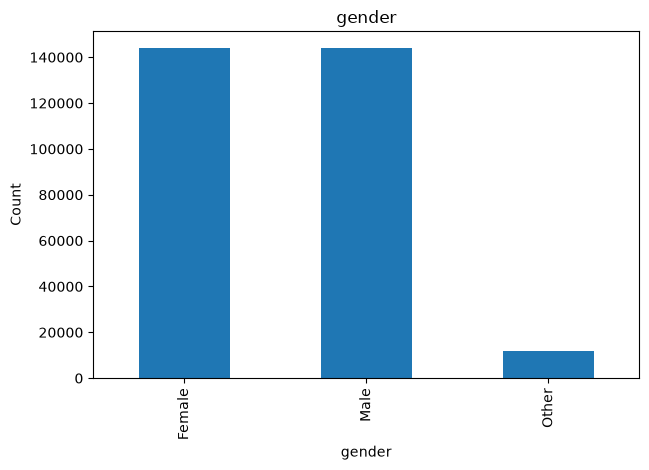

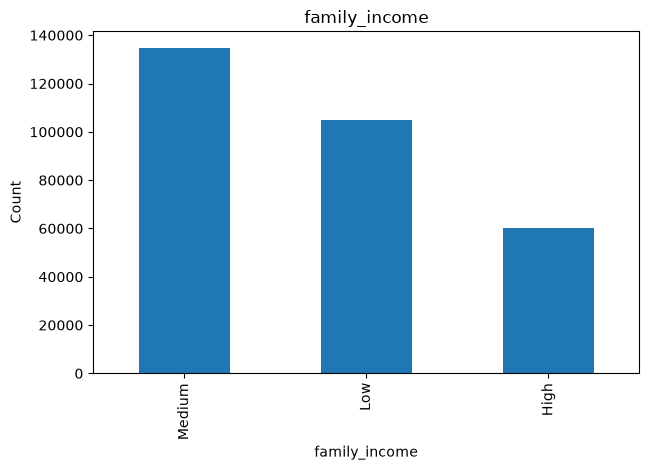

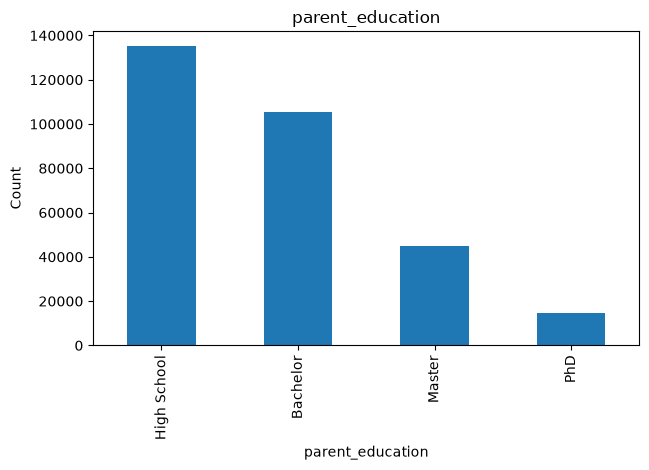

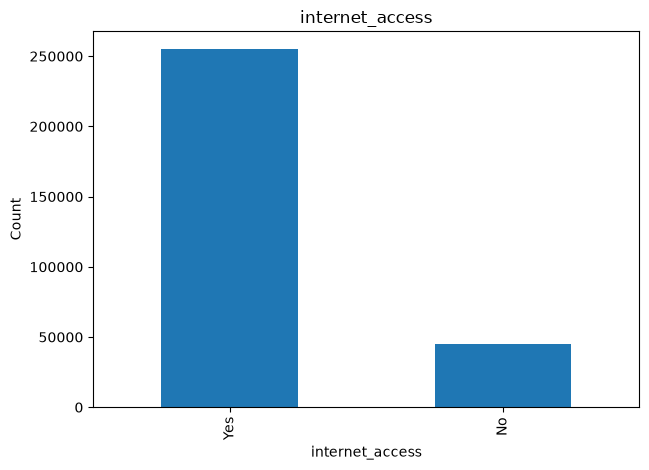

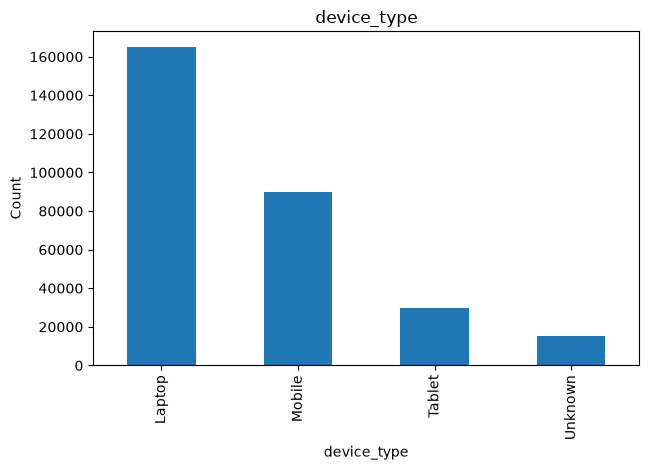

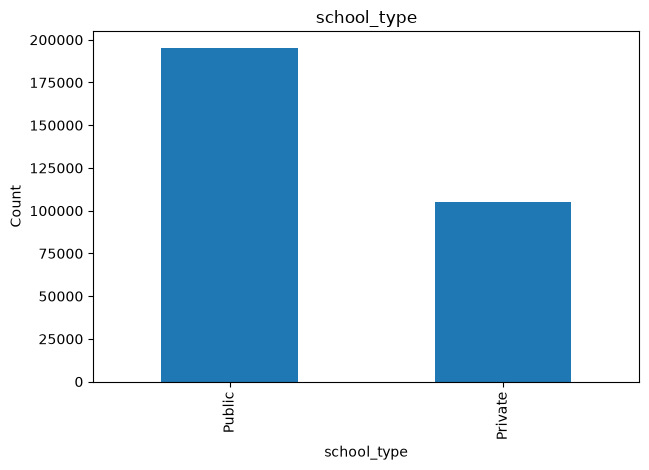

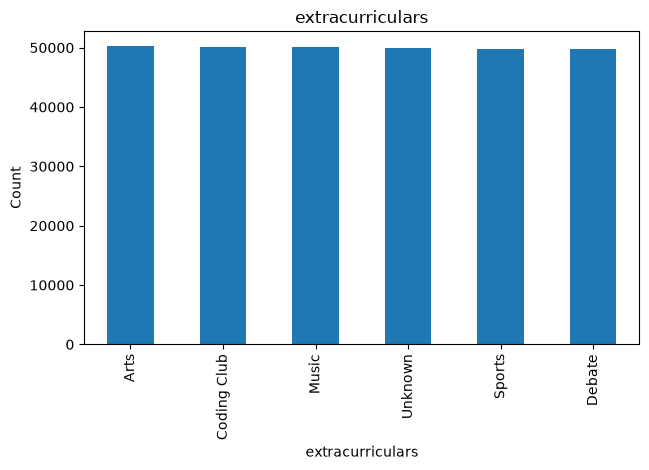

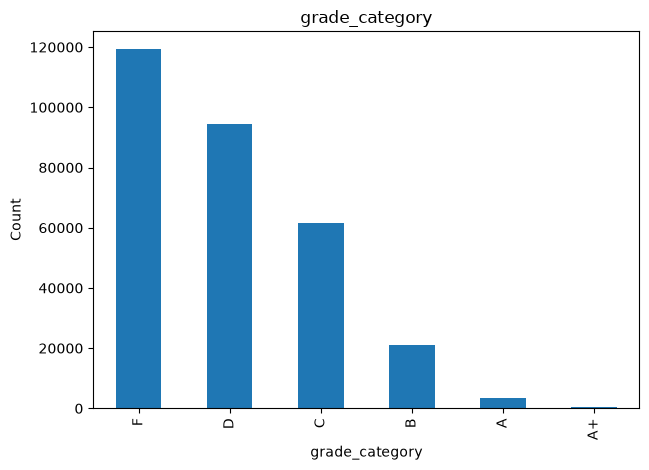

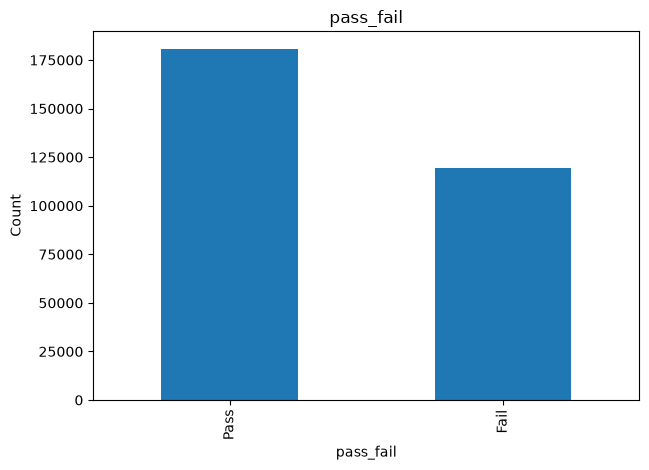

In [39]:
for col in df.select_dtypes(include='object').columns:
    df[col].value_counts().plot(kind='bar', title=col)
    plt.tight_layout()
    plt.ylabel('Count')
    plt.show()

In [40]:
categorical_cols = [
    'gender',
    'family_income',
    'parent_education',
    'internet_access',
    'device_type',
    'school_type',
    'extracurriculars'
]

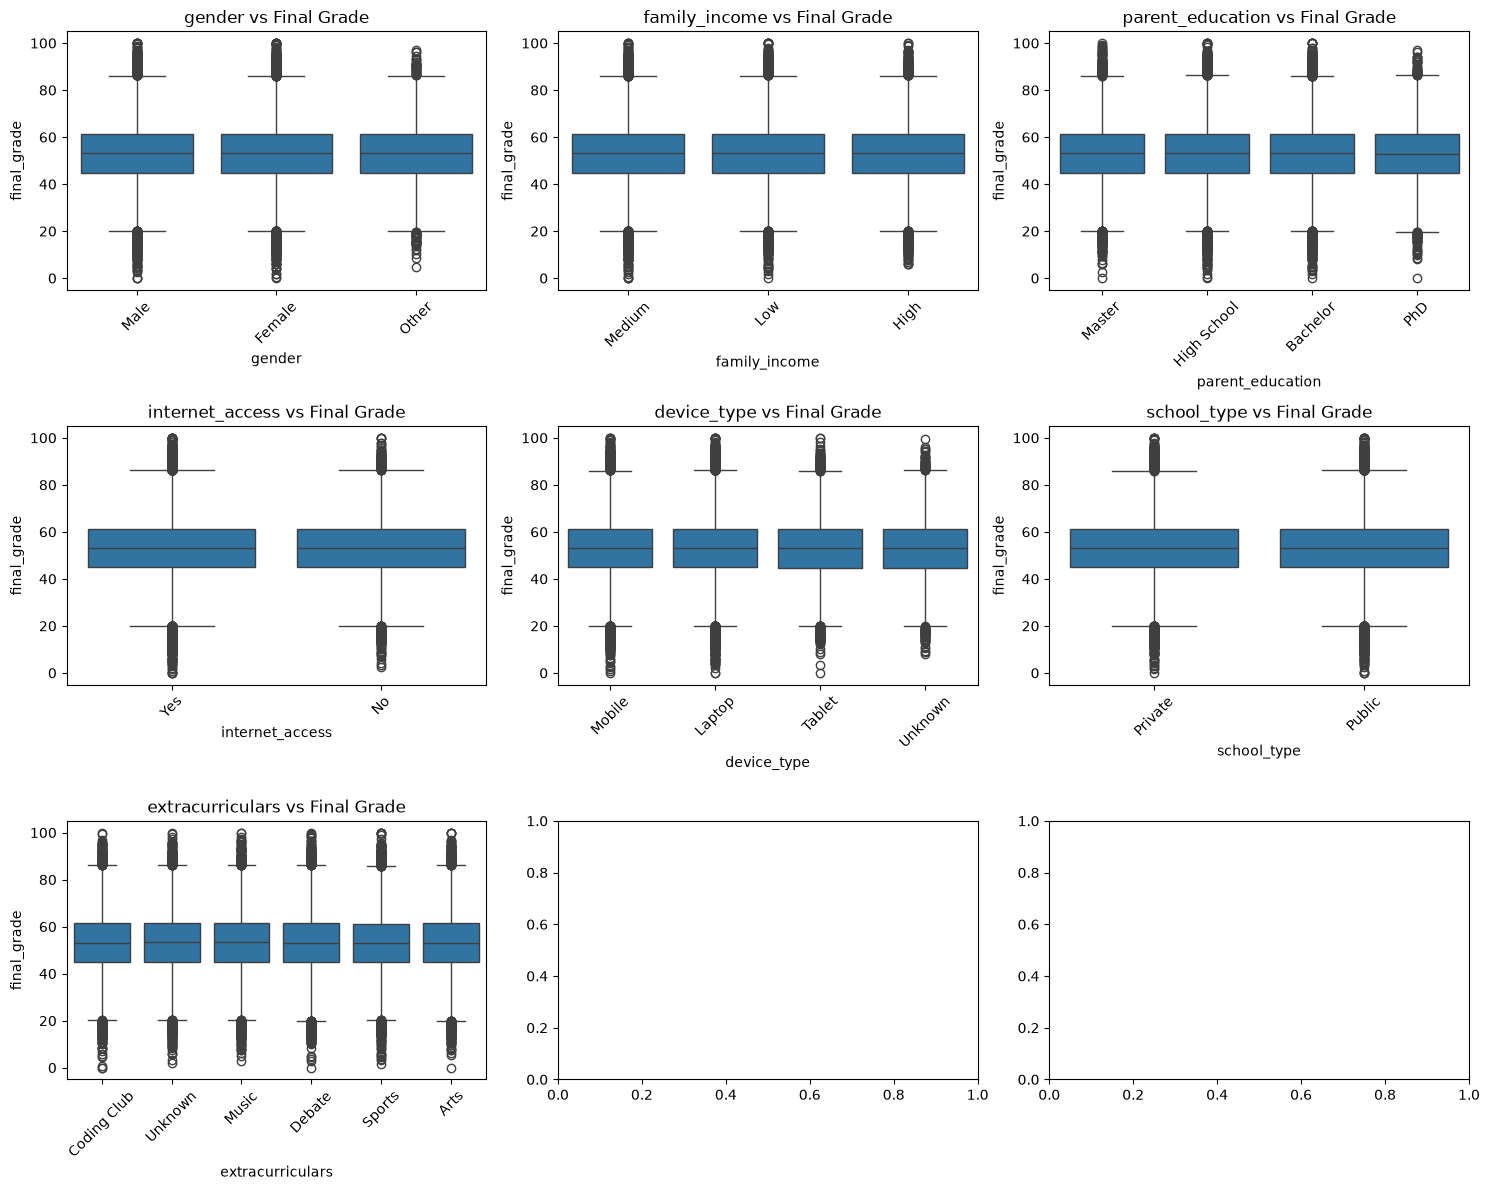

In [41]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, col in zip(axes.flat, categorical_cols):
    sns.boxplot(x=col, y='final_grade', data=df, ax=ax)
    ax.set_title(f'{col} vs Final Grade')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

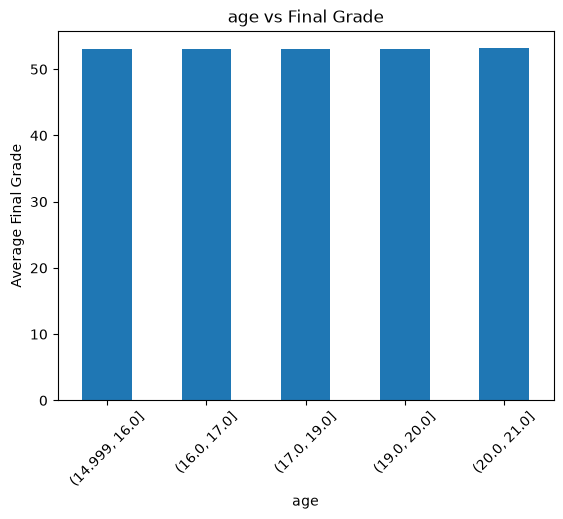

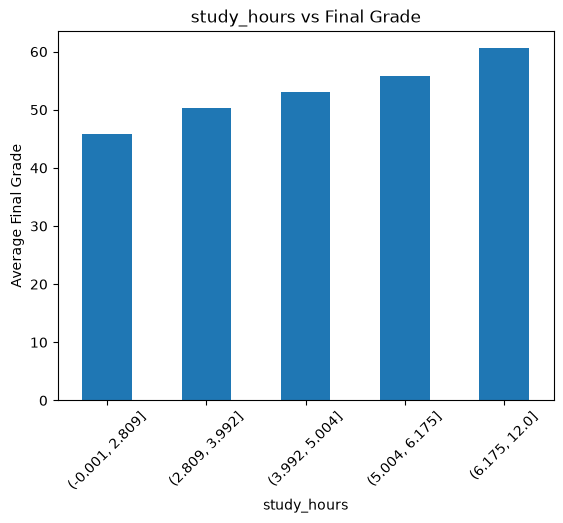

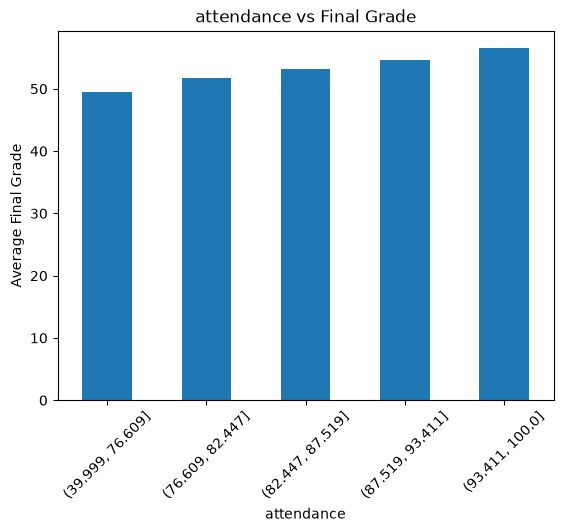

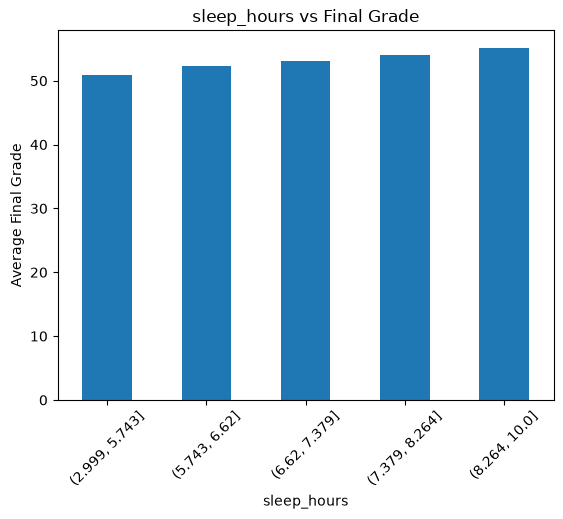

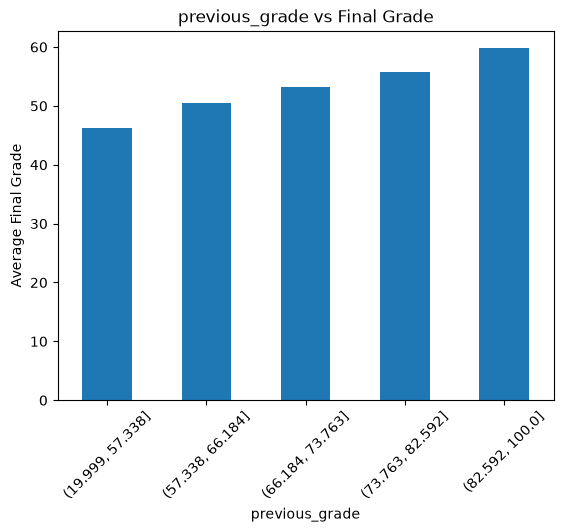

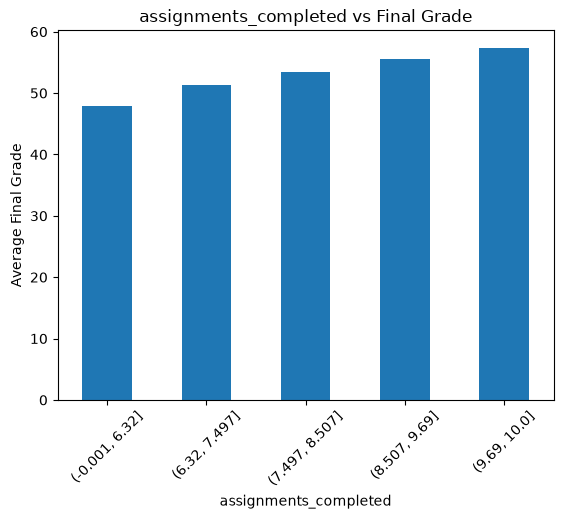

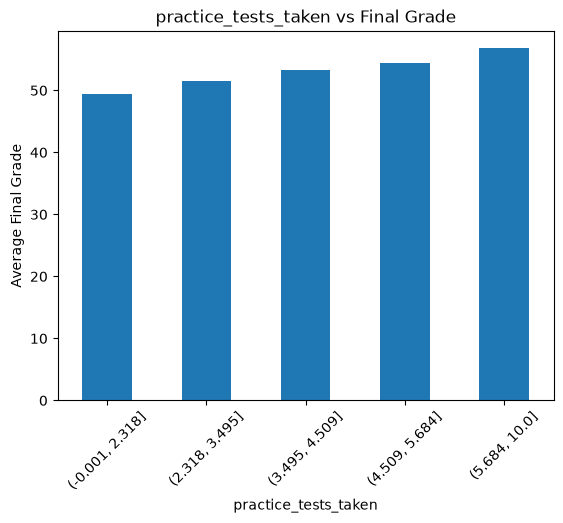

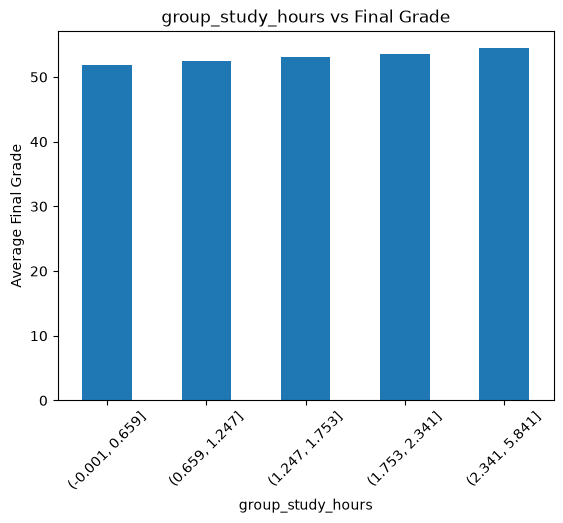

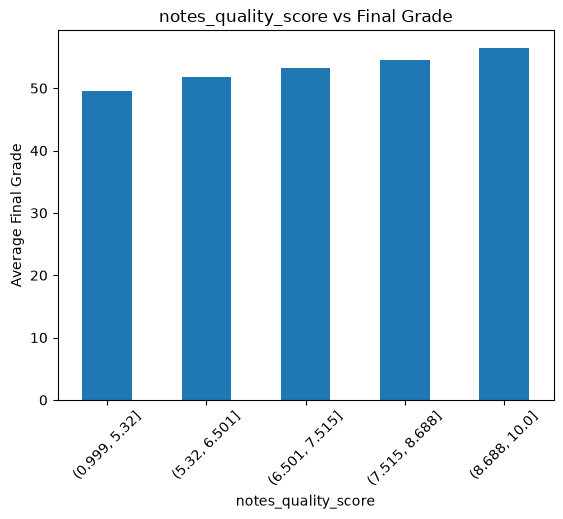

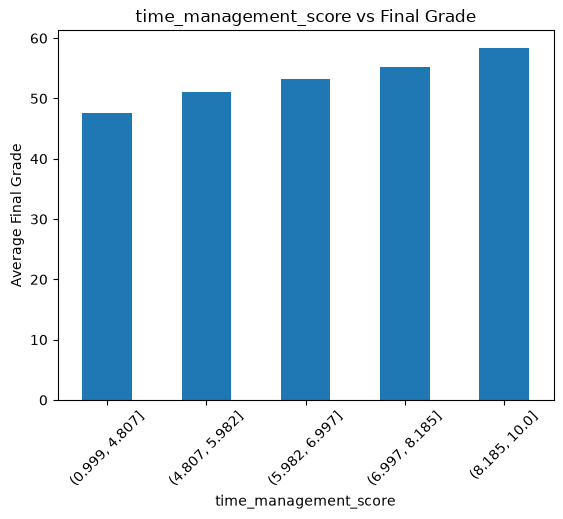

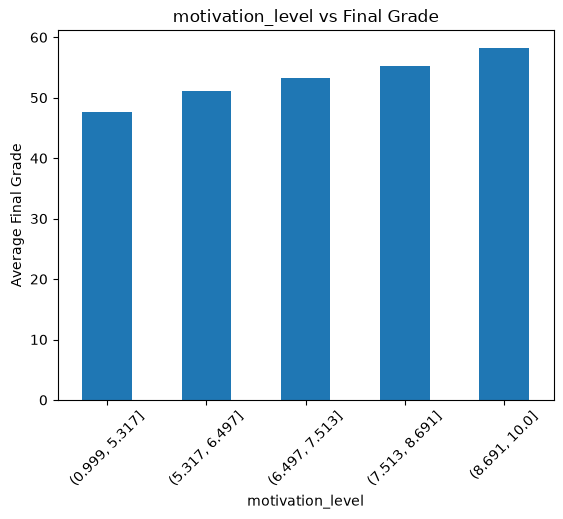

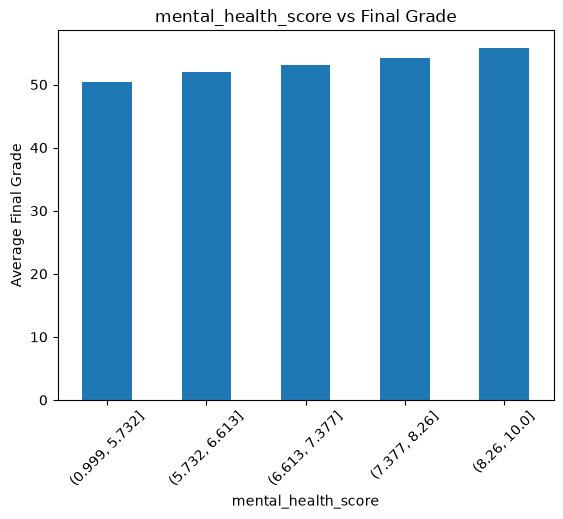

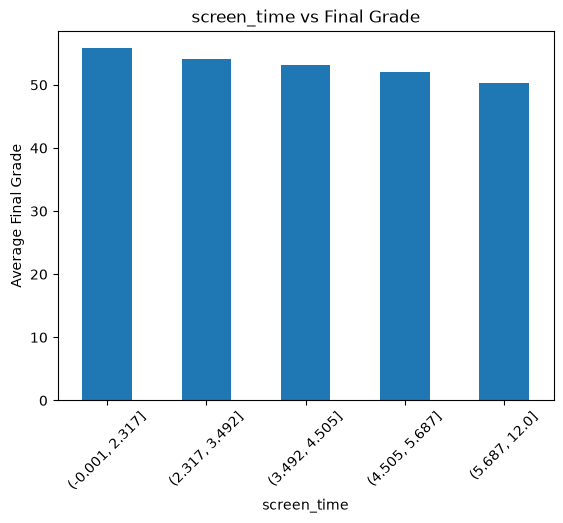

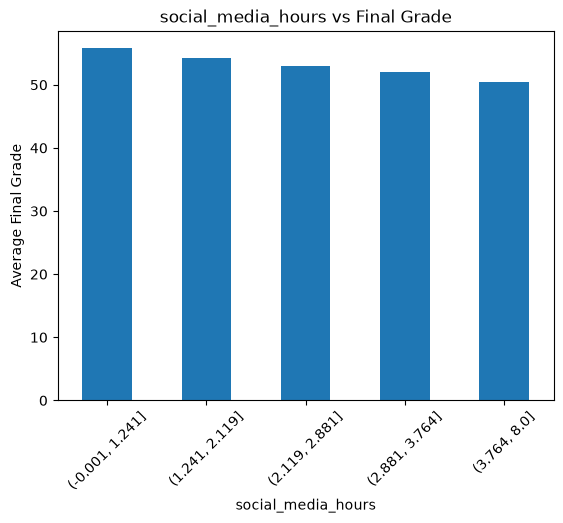

In [42]:
num_cols = df.select_dtypes(include='number').columns.drop('final_grade')

for col in num_cols:
    df.groupby(pd.qcut(df[col], 5, duplicates='drop'))['final_grade'].mean().plot(kind='bar')
    plt.title(f'{col} vs Final Grade')
    plt.ylabel('Average Final Grade')
    plt.xticks(rotation=45)
    plt.show()

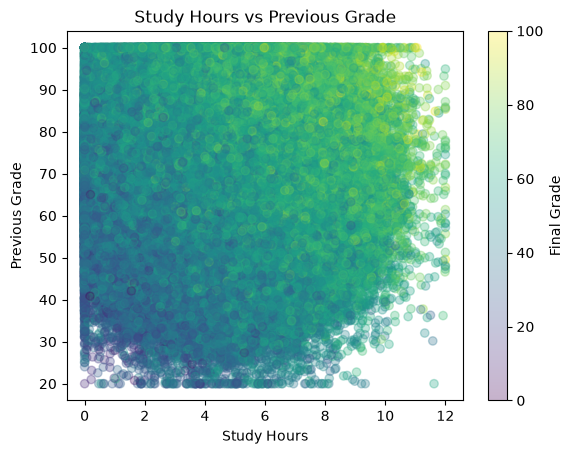

In [43]:
plt.scatter(
    df['study_hours'],
    df['previous_grade'],
    c=df['final_grade'],
    alpha=0.3
)

plt.xlabel('Study Hours')
plt.ylabel('Previous Grade')
plt.title('Study Hours vs Previous Grade')
plt.colorbar(label='Final Grade')

plt.show()

In [44]:
df.select_dtypes(include='number').skew().sort_values(ascending=False)

group_study_hours        0.295120
social_media_hours       0.225141
screen_time              0.127052
practice_tests_taken     0.113223
study_hours              0.070237
age                     -0.000137
final_grade             -0.035994
sleep_hours             -0.092318
previous_grade          -0.118588
mental_health_score     -0.120706
time_management_score   -0.165463
motivation_level        -0.284340
notes_quality_score     -0.289121
attendance              -0.294641
assignments_completed   -0.580593
dtype: float64

In [45]:
for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(df[col].unique())


gender:
<ArrowStringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

family_income:
<ArrowStringArray>
['Medium', 'Low', 'High']
Length: 3, dtype: str

parent_education:
<ArrowStringArray>
['Master', 'High School', 'Bachelor', 'PhD']
Length: 4, dtype: str

internet_access:
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

device_type:
<ArrowStringArray>
['Mobile', 'Laptop', 'Tablet', 'Unknown']
Length: 4, dtype: str

school_type:
<ArrowStringArray>
['Private', 'Public']
Length: 2, dtype: str

extracurriculars:
<ArrowStringArray>
['Coding Club', 'Unknown', 'Music', 'Debate', 'Sports', 'Arts']
Length: 6, dtype: str

grade_category:
<ArrowStringArray>
['D', 'A', 'F', 'C', 'B', 'A+', nan]
Length: 7, dtype: str

pass_fail:
<ArrowStringArray>
['Pass', 'Fail']
Length: 2, dtype: str


In [46]:
df.head()

,age,gender,study_hours,attendance,sleep_hours,previous_grade,assignments_completed,practice_tests_taken,group_study_hours,notes_quality_score,...,social_media_hours,family_income,parent_education,internet_access,device_type,school_type,extracurriculars,final_grade,grade_category,pass_fail
0,21,Male,1.645404,79.154521,8.230886,96.053840,7.719620,1.871170,1.447894,6.811654,...,4.018412,Medium,Master,Yes,Mobile,Private,Coding Club,59.248749,D,Pass
1,18,Male,4.462126,72.526685,6.139219,53.024821,6.754758,5.630071,1.891288,10.000000,...,3.268642,Medium,Master,Yes,Laptop,Public,Unknown,58.595595,D,Pass
2,19,Female,6.220212,98.531716,6.946313,78.775422,10.000000,7.862877,1.774356,6.484908,...,2.327293,Low,High School,Yes,Tablet,Private,Music,85.855289,A,Pass
3,21,Female,1.826644,97.731245,8.297048,76.122618,7.440486,2.316252,1.204271,6.057978,...,1.163367,Medium,Bachelor,Yes,Laptop,Public,Debate,42.117503,F,Fail
4,17,Male,3.789322,78.589107,6.777171,81.305681,9.962609,5.335697,1.399230,9.013332,...,0.411183,High,High School,Yes,Laptop,Private,Debate,62.870474,C,Pass


In [47]:
df = df.drop(columns=['grade_category', 'pass_fail'])

In [48]:
df.shape

(300000, 22)

In [49]:
df.columns

Index(['age', 'gender', 'study_hours', 'attendance', 'sleep_hours',
       'previous_grade', 'assignments_completed', 'practice_tests_taken',
       'group_study_hours', 'notes_quality_score', 'time_management_score',
       'motivation_level', 'mental_health_score', 'screen_time',
       'social_media_hours', 'family_income', 'parent_education',
       'internet_access', 'device_type', 'school_type', 'extracurriculars',
       'final_grade'],
      dtype='str')

DATA PREPROCESSING

In [50]:
X = df.drop(columns = ['final_grade'])
y = df['final_grade']

In [51]:
print(X.shape)
print(y.shape)

(300000, 21)
(300000,)


In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [53]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(240000, 21)
(60000, 21)
(240000,)
(60000,)


In [54]:
num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(include='object').columns

print("Numerical:", list(num_cols))
print("Categorical:", list(cat_cols))

Numerical: ['age', 'study_hours', 'attendance', 'sleep_hours', 'previous_grade', 'assignments_completed', 'practice_tests_taken', 'group_study_hours', 'notes_quality_score', 'time_management_score', 'motivation_level', 'mental_health_score', 'screen_time', 'social_media_hours']
Categorical: ['gender', 'family_income', 'parent_education', 'internet_access', 'device_type', 'school_type', 'extracurriculars']


In [55]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

Linear Regression

In [56]:
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['age','gender','study_hours',...,'device_type','school_type', 'extracurriculars']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

In [57]:
y_pred = linear_model.predict(X_test)

In [58]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 3.998706818376575
RMSE: 5.008636399896874
R²: 0.8310965696816246


Decision Tree

In [59]:
tree_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])

tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['age','gender','study_hours',...,'device_type','school_type', 'extracurriculars']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

In [60]:
y_pred_tree = tree_model.predict(X_test)

In [61]:
mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree")
print("MAE:", mae_tree)
print("RMSE:", rmse_tree)
print("R²:", r2_tree)

Decision Tree
MAE: 7.35595470074559
RMSE: 9.243447468834738
R²: 0.42473571222254713


Random forest

In [62]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['age','gender','study_hours',...,'device_type','school_type', 'extracurriculars']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

In [63]:
y_pred_rf = rf_model.predict(X_test)

In [64]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

Random Forest
MAE: 4.6859744436817845
RMSE: 5.870254919872342
R²: 0.7679864327339282


Gradient Boosting Regressor

In [65]:
gb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(random_state=42))
])

gb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['age','gender','study_hours',...,'device_type','school_type', 'extracurriculars']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

In [66]:
y_pred_gb = gb_model.predict(X_test)

In [67]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting")
print("MAE:", mae_gb)
print("RMSE:", rmse_gb)
print("R²:", r2_gb)

Gradient Boosting
MAE: 4.6196313547669545
RMSE: 5.794228972279399
R²: 0.7739571544328825


XGBoost

In [68]:
xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['age','gender','study_hours',...,'device_type','school_type', 'extracurriculars']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

In [69]:
y_pred_xgb = xgb_model.predict(X_test)

In [70]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost")
print("MAE:", mae_xgb)
print("RMSE:", rmse_xgb)
print("R²:", r2_xgb)

XGBoost
MAE: 4.262093157756727
RMSE: 5.335373906977953
R²: 0.8083410166389334


In [71]:
ann_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', MLPRegressor(
        hidden_layer_sizes=(64, 32),
        max_iter=100,
        random_state=42
    ))
])

ann_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['age','gender','study_hours',...,'device_type','school_type', 'extracurriculars']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

In [72]:
y_pred_ann = ann_model.predict(X_test)

In [73]:
mae_ann = mean_absolute_error(y_test, y_pred_ann)
rmse_ann = np.sqrt(mean_squared_error(y_test, y_pred_ann))
r2_ann = r2_score(y_test, y_pred_ann)

print("ANN")
print("MAE:", mae_ann)
print("RMSE:", rmse_ann)
print("R²:", r2_ann)

ANN
MAE: 4.026114769925851
RMSE: 5.0425368426036306
R²: 0.8288024208589336


DNN

In [74]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape)
print(X_test_processed.shape)

(240000, 38)
(60000, 38)


In [75]:
dnn_model = Sequential([
    Dense(128, activation='relu', input_shape=(38,)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1)
])

dnn_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

dnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,873 (62.00 KB)

 Trainable params: 15,873 (62.00 KB)

 Non-trainable params: 0 (0.00 B)

In [76]:
history = dnn_model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=256,
    verbose=1
)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 172.3321 - mae: 7.8585 - val_loss: 31.5048 - val_mae: 4.4875
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 36.0790 - mae: 4.7761 - val_loss: 95.0749 - val_mae: 8.4651
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 28.3064 - mae: 4.2342 - val_loss: 126.3572 - val_mae: 9.9780
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 27.0413 - mae: 4.1413 - val_loss: 141.5467 - val_mae: 10.6345
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 26.7404 - mae: 4.1186 - val_loss: 153.4694 - val_mae: 11.1697
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 26.4945 - mae: 4.1027 - val_loss: 148.9843 - val_mae: 10.9703
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 26.2087 - mae: 4.0806 - val_loss: 155.1693 - val_mae: 11.2336
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 26.0913 - mae: 4.0728 - val_loss: 142.9156 - val_mae: 10.7071
Epoch 9/20
750/750 ━━━━━━━━━

In [77]:
y_pred_dnn = dnn_model.predict(X_test_processed).flatten()

mae_dnn = mean_absolute_error(y_test, y_pred_dnn)
rmse_dnn = np.sqrt(mean_squared_error(y_test, y_pred_dnn))
r2_dnn = r2_score(y_test, y_pred_dnn)

print("DNN")
print("MAE:", mae_dnn)
print("RMSE:", rmse_dnn)
print("R²:", r2_dnn)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 906us/step
DNN
MAE: 9.257357596494224
RMSE: 10.545182866725838
R²: 0.2513002470376082


In [78]:
from tensorflow.keras.callbacks import EarlyStopping

In [79]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [80]:
history_dnn = dnn_model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 25.2338 - mae: 4.0100 - val_loss: 117.6143 - val_mae: 9.5525
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 25.2472 - mae: 4.0082 - val_loss: 124.5880 - val_mae: 9.8846
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 25.2145 - mae: 4.0075 - val_loss: 128.4736 - val_mae: 10.0742
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 25.1514 - mae: 4.0026 - val_loss: 124.1271 - val_mae: 9.8795


In [81]:
y_pred_dnn_es = dnn_model.predict(X_test_processed).flatten()

mae_dnn_es = mean_absolute_error(y_test, y_pred_dnn_es)
rmse_dnn_es = np.sqrt(mean_squared_error(y_test, y_pred_dnn_es))
r2_dnn_es = r2_score(y_test, y_pred_dnn_es)

print("DNN with Early Stopping")
print("MAE:", mae_dnn_es)
print("RMSE:", rmse_dnn_es)
print("R²:", r2_dnn_es)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 905us/step
DNN with Early Stopping
MAE: 9.578564066648344
RMSE: 10.860765758592272
R²: 0.20581742643936995


In [82]:
improved_dnn = Sequential([
    Dense(64, activation='relu', input_shape=(38,)),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

improved_dnn.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

improved_dnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 64)             │         2,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,121 (20.00 KB)

 Trainable params: 5,121 (20.00 KB)

 Non-trainable params: 0 (0.00 B)

In [83]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history_improved = improved_dnn.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 259.0807 - mae: 9.8721 - val_loss: 29.4842 - val_mae: 4.3371
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 53.0588 - mae: 5.7800 - val_loss: 27.6774 - val_mae: 4.1971
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 47.5209 - mae: 5.4626 - val_loss: 51.8875 - val_mae: 5.9322
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 33.6168 - mae: 4.5640 - val_loss: 113.8338 - val_mae: 9.3932
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 30.7069 - mae: 4.3627 - val_loss: 143.0360 - val_mae: 10.7213


In [84]:
y_pred_improved = improved_dnn.predict(X_test_processed).flatten()

mae_improved = mean_absolute_error(y_test, y_pred_improved)
rmse_improved = np.sqrt(mean_squared_error(y_test, y_pred_improved))
r2_improved = r2_score(y_test, y_pred_improved)

print("Improved DNN")
print("MAE:", mae_improved)
print("RMSE:", rmse_improved)
print("R²:", r2_improved)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 907us/step
Improved DNN
MAE: 4.2024113957185465
RMSE: 5.26216370714235
R²: 0.8135646900681834


Comparison

In [85]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting',
        'XGBoost',
        'ANN / MLP',
        'Original DNN',
        'Improved DNN'
    ],
    'MAE': [
        mae,
        mae_tree,
        mae_rf,
        mae_gb,
        mae_xgb,
        mae_ann,
        mae_dnn,
        mae_improved
    ],
    'RMSE': [
        rmse,
        rmse_tree,
        rmse_rf,
        rmse_gb,
        rmse_xgb,
        rmse_ann,
        rmse_dnn,
        rmse_improved
    ],
    'R2': [
        r2,
        r2_tree,
        r2_rf,
        r2_gb,
        r2_xgb,
        r2_ann,
        r2_dnn,
        r2_improved
    ]
})

results = results.sort_values('R2', ascending=False)

print(results)

               Model       MAE       RMSE        R2
0  Linear Regression  3.998707   5.008636  0.831097
5          ANN / MLP  4.026115   5.042537  0.828802
7       Improved DNN  4.202411   5.262164  0.813565
4            XGBoost  4.262093   5.335374  0.808341
3  Gradient Boosting  4.619631   5.794229  0.773957
2      Random Forest  4.685974   5.870255  0.767986
1      Decision Tree  7.355955   9.243447  0.424736
6       Original DNN  9.257358  10.545183  0.251300


tune XGBoost

In [86]:
xgb = XGBRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=8,
    scoring='neg_mean_squared_error',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_processed, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("Best CV RMSE:")
print(np.sqrt(-random_search.best_score_))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters:
{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best CV RMSE:
5.130041836094231


In [87]:
best_xgb = XGBRegressor(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=1.0,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

best_xgb.fit(X_train_processed, y_train)

y_pred_best_xgb = best_xgb.predict(X_test_processed)

mae_best_xgb = mean_absolute_error(y_test, y_pred_best_xgb)
rmse_best_xgb = np.sqrt(mean_squared_error(y_test, y_pred_best_xgb))
r2_best_xgb = r2_score(y_test, y_pred_best_xgb)

print("Tuned XGBoost")
print("MAE:", mae_best_xgb)
print("RMSE:", rmse_best_xgb)
print("R²:", r2_best_xgb)

Tuned XGBoost
MAE: 4.094740142611048
RMSE: 5.129193158309748
R²: 0.8228677791650746


tune ANN

In [88]:
X_tune = X_train_processed[:50000]
y_tune = y_train.iloc[:50000]

ann = MLPRegressor(
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=42
)

ann_param_grid = {
    'hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64)],
    'learning_rate_init': [0.001, 0.005],
    'alpha': [0.0001, 0.001],
    'batch_size': [128, 256]
}

ann_search = RandomizedSearchCV(
    estimator=ann,
    param_distributions=ann_param_grid,
    n_iter=6,
    scoring='neg_mean_squared_error',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

ann_search.fit(X_tune, y_tune)

print("Best Parameters:")
print(ann_search.best_params_)

print("\nBest CV RMSE:")
print((-ann_search.best_score_) ** 0.5)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters:
{'learning_rate_init': 0.001, 'hidden_layer_sizes': (32,), 'batch_size': 256, 'alpha': 0.001}

Best CV RMSE:
5.00836491200127


In [89]:
best_ann = MLPRegressor(
    hidden_layer_sizes=(32,),
    learning_rate_init=0.001,
    batch_size=256,
    alpha=0.001,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=42
)

best_ann.fit(X_train_processed, y_train)

y_pred_ann_tuned = best_ann.predict(X_test_processed)

mae_ann_tuned = mean_absolute_error(y_test, y_pred_ann_tuned)
rmse_ann_tuned = mean_squared_error(y_test, y_pred_ann_tuned) ** 0.5
r2_ann_tuned = r2_score(y_test, y_pred_ann_tuned)

print("Tuned ANN")
print("MAE:", mae_ann_tuned)
print("RMSE:", rmse_ann_tuned)
print("R²:", r2_ann_tuned)

Tuned ANN
MAE: 4.000712162857327
RMSE: 5.010818404910494
R²: 0.8309493725680536


Final Comparison

In [90]:
results = {
    "Linear Regression": [mae, rmse, r2],
    "Decision Tree": [mae_tree, rmse_tree, r2_tree],
    "Random Forest": [mae_rf, rmse_rf, r2_rf],
    "Gradient Boosting": [mae_gb, rmse_gb, r2_gb],
    "XGBoost (Tuned)": [4.094740142611048, 5.129193158309748, 0.8228677791650746],
    "ANN / MLP (Tuned)": [mae_ann_tuned, rmse_ann_tuned, r2_ann_tuned],
    "Original DNN": [9.6895586797967, 10.96488520635814, 0.19051717665922108],
    "Improved DNN": [4.433960484797757, 5.546928412523128, 0.7928406302236755]
}

results_df = pd.DataFrame(
    results,
    index=["MAE", "RMSE", "R²"]
).T.sort_values("R²", ascending=False)

print(results_df)

                        MAE       RMSE        R²
Linear Regression  3.998707   5.008636  0.831097
ANN / MLP (Tuned)  4.000712   5.010818  0.830949
XGBoost (Tuned)    4.094740   5.129193  0.822868
Improved DNN       4.433960   5.546928  0.792841
Gradient Boosting  4.619631   5.794229  0.773957
Random Forest      4.685974   5.870255  0.767986
Decision Tree      7.355955   9.243447  0.424736
Original DNN       9.689559  10.964885  0.190517


In [91]:
final_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Train on the complete training data
final_model.fit(X_train, y_train)

# Save the complete pipeline
joblib.dump(final_model, 'student_performance_model.pkl')

print("Final model saved successfully!")

Final model saved successfully!


In [92]:
loaded_model = joblib.load('student_performance_model.pkl')

test_prediction = loaded_model.predict(X_test.iloc[:5])

print("Sample predictions:")
print(test_prediction)

Sample predictions:
[66.8788405  68.20413417 66.56726982 70.75384561 57.22695905]


In [93]:
# Baseline feature sets
feature_sets = {
    "All Features": X.columns.tolist(),
    "Without Age": [col for col in X.columns if col != "age"],
    "Without Gender": [col for col in X.columns if col != "gender"],
    "Without Age & Gender": [
        col for col in X.columns
        if col not in ["age", "gender"]
    ]
}

results = []

for name, features in feature_sets.items():

    X_train_subset = X_train[features]
    X_test_subset = X_test[features]

    num_cols_subset = X_train_subset.select_dtypes(
        include=np.number
    ).columns.tolist()

    cat_cols_subset = X_train_subset.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    preprocessor_subset = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols_subset),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_subset)
        ]
    )

    model = Pipeline([
        ("preprocessor", preprocessor_subset),
        ("model", LinearRegression())
    ])

    model.fit(X_train_subset, y_train)

    predictions = model.predict(X_test_subset)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Feature Set": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

ablation_results = pd.DataFrame(results)

ablation_results

,Feature Set,MAE,RMSE,R²
0,All Features,3.998707,5.008636,0.831097
1,Without Age,3.998663,5.008597,0.831099
2,Without Gender,3.998707,5.008635,0.831097
3,Without Age & Gender,3.998664,5.008596,0.831099


In [94]:
background_features = [
    "family_income",
    "parent_education",
    "internet_access",
    "device_type",
    "school_type",
    "extracurriculars"
]

feature_sets_bg = {
    "All Features": X.columns.tolist()
}

# Remove each background feature individually
for feature in background_features:
    feature_name = feature.replace("_", " ").title()
    feature_sets_bg[f"Without {feature_name}"] = [
        col for col in X.columns if col != feature
    ]

# Remove all background features together
feature_sets_bg["Without All Background Features"] = [
    col for col in X.columns if col not in background_features
]

results_bg = []

for name, features in feature_sets_bg.items():

    X_train_subset = X_train[features]
    X_test_subset = X_test[features]

    num_cols_subset = X_train_subset.select_dtypes(
        include=np.number
    ).columns.tolist()

    cat_cols_subset = X_train_subset.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    preprocessor_subset = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols_subset),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_subset)
        ]
    )

    model = Pipeline([
        ("preprocessor", preprocessor_subset),
        ("model", LinearRegression())
    ])

    model.fit(X_train_subset, y_train)

    predictions = model.predict(X_test_subset)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results_bg.append({
        "Feature Set": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

background_ablation_results = pd.DataFrame(results_bg)

background_ablation_results

,Feature Set,MAE,RMSE,R²
0,All Features,3.998707,5.008636,0.831097
1,Without Family Income,3.998617,5.008549,0.831102
2,Without Parent Education,3.998623,5.008536,0.831103
3,Without Internet Access,3.998703,5.008631,0.831097
4,Without Device Type,3.998687,5.008611,0.831098
5,Without School Type,3.998682,5.008599,0.831099
6,Without Extracurriculars,3.998706,5.008673,0.831094
7,Without All Background Features,3.998499,5.008417,0.831111


EXPERIMENT 1: SelectKBest + Linear Regression

In [95]:
# ============================================================
# EXPERIMENT 1: SelectKBest + Linear Regression
# ============================================================

from sklearn.feature_selection import SelectKBest, f_regression

# Try different numbers of selected features
k_values = [5, 10, 15, 20, 'all']

results_selectk = []

for k in k_values:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('selector', SelectKBest(score_func=f_regression, k=k)),
        ('model', LinearRegression())
    ])

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results_selectk.append({
        'k': k,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

# Display results
results_selectk_df = pd.DataFrame(results_selectk)

print("\nSelectKBest + Linear Regression Results:")
print(results_selectk_df.to_string(index=False))


SelectKBest + Linear Regression Results:
  k      MAE     RMSE       R2
  5 6.066070 7.602339 0.610871
 10 4.490442 5.618421 0.787466
 15 3.998380 5.008227 0.831124
 20 3.998496 5.008442 0.831110
all 3.998707 5.008636 0.831097


 EXPERIMENT 2: Polynomial Features + Ridge Regression

In [96]:
# ============================================================
# EXPERIMENT 2: Polynomial Features + Ridge Regression
# ============================================================

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

degrees = [1, 2]

results_poly = []

for degree in degrees:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('model', Ridge(alpha=1.0))
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results_poly.append({
        'degree': degree,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

results_poly_df = pd.DataFrame(results_poly)

print("\nPolynomial Features + Ridge Results:")
print(results_poly_df.to_string(index=False))


Polynomial Features + Ridge Results:
 degree      MAE     RMSE       R2
      1 3.998707 5.008636 0.831097
      2 4.002962 5.013049 0.830799


EXPERIMENT 3: Regularized Linear Models
Ridge, Lasso, ElasticNet

In [97]:
# ============================================================
# EXPERIMENT 3: Regularized Linear Models
# Ridge, Lasso, ElasticNet
# ============================================================

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

alphas = [0.001, 0.01, 0.1, 1, 10, 100]

results_regularized = []

# -------------------------
# Ridge
# -------------------------
for alpha in alphas:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('model', Ridge(alpha=alpha))
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results_regularized.append({
        'Model': 'Ridge',
        'alpha': alpha,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    })


# -------------------------
# Lasso
# -------------------------
for alpha in alphas:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('model', Lasso(alpha=alpha, max_iter=10000))
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results_regularized.append({
        'Model': 'Lasso',
        'alpha': alpha,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    })


# -------------------------
# ElasticNet
# -------------------------
for alpha in alphas:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('model', ElasticNet(
            alpha=alpha,
            l1_ratio=0.5,
            max_iter=10000
        ))
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results_regularized.append({
        'Model': 'ElasticNet',
        'alpha': alpha,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    })


# -------------------------
# Display results
# -------------------------

results_regularized_df = pd.DataFrame(results_regularized)

print("\nRegularized Linear Model Results:")
print(results_regularized_df.to_string(index=False))


Regularized Linear Model Results:
     Model   alpha      MAE      RMSE        R2
     Ridge   0.001 3.998707  5.008636  0.831097
     Ridge   0.010 3.998707  5.008636  0.831097
     Ridge   0.100 3.998707  5.008636  0.831097
     Ridge   1.000 3.998707  5.008636  0.831097
     Ridge  10.000 3.998704  5.008634  0.831097
     Ridge 100.000 3.998683  5.008612  0.831098
     Lasso   0.001 3.998573  5.008470  0.831108
     Lasso   0.010 3.998382  5.008233  0.831124
     Lasso   0.100 4.006685  5.018400  0.830437
     Lasso   1.000 4.889214  6.123987  0.747496
     Lasso  10.000 9.724481 12.187214 -0.000019
     Lasso 100.000 9.724481 12.187214 -0.000019
ElasticNet   0.001 3.998610  5.008519  0.831104
ElasticNet   0.010 3.998530  5.008411  0.831112
ElasticNet   0.100 4.032346  5.051277  0.828208
ElasticNet   1.000 5.528367  6.930860  0.676575
ElasticNet  10.000 9.708018 12.166687  0.003347
ElasticNet 100.000 9.724481 12.187214 -0.000019


Experiment 4: Properly Tuned XGBoost

In [98]:
# ============================================================
# EXPERIMENT 4: Properly Tuned XGBoost
# ============================================================

from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# XGBoost model
xgb_model = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# Pipeline
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', xgb_model)
])

# Wider hyperparameter search
param_dist = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [2, 3, 4, 5, 6, 8],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'model__min_child_weight': [1, 3, 5, 10],
    'model__gamma': [0, 0.1, 0.3, 0.5],
    'model__reg_alpha': [0, 0.01, 0.1],
    'model__reg_lambda': [1, 5, 10]
}

# Randomized search
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

print("Starting XGBoost hyperparameter search...")

xgb_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(xgb_search.best_params_)

print("\nBest CV RMSE:")
print(-xgb_search.best_score_)

# ------------------------------------------------------------
# Evaluate best model on untouched test set
# ------------------------------------------------------------

best_xgb = xgb_search.best_estimator_

y_pred_xgb = best_xgb.predict(X_test)

xgb_mae = mean_absolute_error(y_test, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
xgb_r2 = r2_score(y_test, y_pred_xgb)

print("\nFinal XGBoost Test Results:")
print(f"MAE  : {xgb_mae:.6f}")
print(f"RMSE : {xgb_rmse:.6f}")
print(f"R2   : {xgb_r2:.6f}")

Starting XGBoost hyperparameter search...
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best Parameters:
{'model__subsample': 0.9, 'model__reg_lambda': 1, 'model__reg_alpha': 0.1, 'model__n_estimators': 500, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.1, 'model__gamma': 0, 'model__colsample_bytree': 0.9}

Best CV RMSE:
5.080383135673912

Final XGBoost Test Results:
MAE  : 4.063096
RMSE : 5.089271
R2   : 0.825614


EXPERIMENT 5: Feature Engineering + Linear Regression

In [99]:
# ============================================================
# EXPERIMENT 5: Feature Engineering + Linear Regression
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Create copies so the original X remains unchanged
# ------------------------------------------------------------

X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# ------------------------------------------------------------
# 1. Assignment completion rate
# ------------------------------------------------------------
# Maximum in the dataset is 10 assignments.
# This represents the proportion of assignments completed.

X_train_fe['assignment_completion_rate'] = (
    X_train_fe['assignments_completed'] / 10
)

X_test_fe['assignment_completion_rate'] = (
    X_test_fe['assignments_completed'] / 10
)


# ------------------------------------------------------------
# 2. Study + attendance interaction
# ------------------------------------------------------------
# Captures the combination of study effort and attendance.

X_train_fe['study_attendance'] = (
    X_train_fe['study_hours'] *
    X_train_fe['attendance'] / 100
)

X_test_fe['study_attendance'] = (
    X_test_fe['study_hours'] *
    X_test_fe['attendance'] / 100
)


# ------------------------------------------------------------
# 3. Study + previous-grade interaction
# ------------------------------------------------------------
# Captures how study effort relates to prior academic level.

X_train_fe['study_previous_grade'] = (
    X_train_fe['study_hours'] *
    X_train_fe['previous_grade'] / 100
)

X_test_fe['study_previous_grade'] = (
    X_test_fe['study_hours'] *
    X_test_fe['previous_grade'] / 100
)


# ------------------------------------------------------------
# 4. Academic practice activity
# ------------------------------------------------------------
# Combines assignments and practice tests.

X_train_fe['practice_activity'] = (
    X_train_fe['assignments_completed'] +
    X_train_fe['practice_tests_taken']
)

X_test_fe['practice_activity'] = (
    X_test_fe['assignments_completed'] +
    X_test_fe['practice_tests_taken']
)


# ------------------------------------------------------------
# 5. Study-management interaction
# ------------------------------------------------------------
# Combines study time with time-management ability.

X_train_fe['study_time_management'] = (
    X_train_fe['study_hours'] *
    X_train_fe['time_management_score']
)

X_test_fe['study_time_management'] = (
    X_test_fe['study_hours'] *
    X_test_fe['time_management_score']
)


# ------------------------------------------------------------
# Train Linear Regression
# ------------------------------------------------------------

model_fe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

model_fe.fit(X_train_fe, y_train)

# Predictions
y_pred_fe = model_fe.predict(X_test_fe)

# Metrics
fe_mae = mean_absolute_error(y_test, y_pred_fe)
fe_rmse = np.sqrt(mean_squared_error(y_test, y_pred_fe))
fe_r2 = r2_score(y_test, y_pred_fe)

print("\nFeature Engineering + Linear Regression Results:")
print(f"MAE  : {fe_mae:.6f}")
print(f"RMSE : {fe_rmse:.6f}")
print(f"R2   : {fe_r2:.6f}")


Feature Engineering + Linear Regression Results:
MAE  : 3.998707
RMSE : 5.008636
R2   : 0.831097


In [100]:
# ============================================================
# TARGET RELATIONSHIP CHECK
# ============================================================

print("Final Grade Correlations:")
print(
    df.select_dtypes(include=np.number)
      .corr()['final_grade']
      .sort_values(ascending=False)
)

Final Grade Correlations:
final_grade              1.000000
study_hours              0.430957
previous_grade           0.393373
time_management_score    0.312778
motivation_level         0.306361
assignments_completed    0.282054
practice_tests_taken     0.213146
attendance               0.204748
notes_quality_score      0.201487
mental_health_score      0.159313
sleep_hours              0.122948
group_study_hours        0.075739
age                     -0.000644
social_media_hours      -0.157292
screen_time             -0.157975
Name: final_grade, dtype: float64


In [101]:
print("\nDataset information:")
print(df.dtypes)

print("\nFinal grade statistics:")
print(df['final_grade'].describe())


Dataset information:
age                        int64
gender                       str
study_hours              float64
attendance               float64
sleep_hours              float64
previous_grade           float64
assignments_completed    float64
practice_tests_taken     float64
group_study_hours        float64
notes_quality_score      float64
time_management_score    float64
motivation_level         float64
mental_health_score      float64
screen_time              float64
social_media_hours       float64
family_income                str
parent_education             str
internet_access              str
device_type                  str
school_type                  str
extracurriculars             str
final_grade              float64
dtype: object

Final grade statistics:
count    300000.000000
mean         53.089206
std          12.225161
min           0.000000
25%          44.867737
50%          53.167495
75%          61.379373
max         100.000000
Name: final_grade, dtype: flo

In [102]:
# ============================================================
# PREVIOUS GRADE ANALYSIS
# ============================================================

# Correlation
print("Correlation:", df['previous_grade'].corr(df['final_grade']))

# Group previous grades into 10 bins
prev_grade_groups = pd.qcut(
    df['previous_grade'],
    q=10,
    duplicates='drop'
)

group_analysis = df.groupby(
    prev_grade_groups,
    observed=True
)['final_grade'].agg(['mean', 'std', 'count'])

print("\nFinal grade by previous-grade decile:")
print(group_analysis)

Correlation: 0.3933734516883511

Final grade by previous-grade decile:
                       mean        std  count
previous_grade                               
(19.999, 50.715]  44.535636  11.455811  30000
(50.715, 57.338]  48.019581  11.269430  30000
(57.338, 62.11]   49.799382  11.325414  30000
(62.11, 66.184]   51.111043  11.263644  30000
(66.184, 69.956]  52.575945  11.133691  30000
(69.956, 73.763]  53.700376  11.237239  30000
(73.763, 77.809]  55.013708  11.244419  30000
(77.809, 82.592]  56.544283  11.189937  30000
(82.592, 89.161]  58.300955  11.209923  30000
(89.161, 100.0]   61.291154  11.373252  30000


In [103]:
# ============================================================
# SIMPLE MODEL: PREVIOUS GRADE ONLY
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

X_prev = df[['previous_grade']]
y_prev = df['final_grade']

X_prev_train, X_prev_test, y_prev_train, y_prev_test = train_test_split(
    X_prev,
    y_prev,
    test_size=0.2,
    random_state=42
)

prev_model = LinearRegression()
prev_model.fit(X_prev_train, y_prev_train)

prev_pred = prev_model.predict(X_prev_test)

print("\nPrevious Grade Only:")
print("R2   :", r2_score(y_prev_test, prev_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_prev_test, prev_pred)))


Previous Grade Only:
R2   : 0.15836559110452886
RMSE : 11.180520229707083


EXPERIMENT 6: ACTIONABLE FEATURES ONLY

In [104]:
# ============================================================
# EXPERIMENT 6: ACTIONABLE FEATURES ONLY
# ============================================================

actionable_features = [
    'study_hours',
    'attendance',
    'sleep_hours',
    'previous_grade',
    'assignments_completed',
    'practice_tests_taken',
    'group_study_hours',
    'notes_quality_score',
    'time_management_score',
    'motivation_level',
    'mental_health_score',
    'screen_time',
    'social_media_hours'
]

X_actionable = df[actionable_features]
y_actionable = df['final_grade']

X_train_action, X_test_action, y_train_action, y_test_action = train_test_split(
    X_actionable,
    y_actionable,
    test_size=0.2,
    random_state=42
)

action_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), actionable_features)
    ]
)

action_model = Pipeline([
    ('preprocessor', action_preprocessor),
    ('model', LinearRegression())
])

action_model.fit(X_train_action, y_train_action)

y_pred_action = action_model.predict(X_test_action)

action_mae = mean_absolute_error(y_test_action, y_pred_action)
action_rmse = np.sqrt(mean_squared_error(y_test_action, y_pred_action))
action_r2 = r2_score(y_test_action, y_pred_action)

print("\nActionable Features Only:")
print(f"MAE  : {action_mae:.6f}")
print(f"RMSE : {action_rmse:.6f}")
print(f"R2   : {action_r2:.6f}")


Actionable Features Only:
MAE  : 3.998455
RMSE : 5.008376
R2   : 0.831114


EXPERIMENT 7: 5-FOLD CROSS-VALIDATION

In [105]:
# ============================================================
# EXPERIMENT 7: 5-FOLD CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import KFold, cross_validate

# ------------------------------------------------------------
# 1. Full Linear Regression
# ------------------------------------------------------------

full_cv_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])


# ------------------------------------------------------------
# 2. Actionable Features Linear Regression
# ------------------------------------------------------------

action_cv_model = Pipeline([
    ('preprocessor', action_preprocessor),
    ('model', LinearRegression())
])


# ------------------------------------------------------------
# 3. 5-Fold Cross Validation
# ------------------------------------------------------------

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}


# Full model
full_cv = cross_validate(
    full_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)


# Actionable model
action_cv = cross_validate(
    action_cv_model,
    X_train_action,
    y_train_action,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n==============================")
print("FULL LINEAR REGRESSION")
print("==============================")

print(f"CV MAE  : {-full_cv['test_MAE'].mean():.6f}")
print(f"CV RMSE : {-full_cv['test_RMSE'].mean():.6f}")
print(f"CV R2   : {full_cv['test_R2'].mean():.6f}")
print(f"R2 Std  : {full_cv['test_R2'].std():.6f}")


print("\n==============================")
print("ACTIONABLE LINEAR REGRESSION")
print("==============================")

print(f"CV MAE  : {-action_cv['test_MAE'].mean():.6f}")
print(f"CV RMSE : {-action_cv['test_RMSE'].mean():.6f}")
print(f"CV R2   : {action_cv['test_R2'].mean():.6f}")
print(f"R2 Std  : {action_cv['test_R2'].std():.6f}")


print("\n==============================")
print("INDIVIDUAL FOLD R2")
print("==============================")

print("Full model      :", full_cv['test_R2'])
print("Actionable model:", action_cv['test_R2'])


FULL LINEAR REGRESSION
CV MAE  : 3.984652
CV RMSE : 4.994040
CV R2   : 0.833377
R2 Std  : 0.000398

ACTIONABLE LINEAR REGRESSION
CV MAE  : 3.984381
CV RMSE : 4.993778
CV R2   : 0.833395
R2 Std  : 0.000397

INDIVIDUAL FOLD R2
Full model      : [0.83397713 0.83292332 0.83323987 0.83369416 0.83305138]
Actionable model: [0.83398843 0.83296859 0.83324077 0.83372584 0.83304938]


FINALLLLLL

In [106]:
# ============================================================
# FINAL ACTIONABLE MODEL
# ============================================================

import joblib

# Final 13 features
final_features = [
    'study_hours',
    'attendance',
    'sleep_hours',
    'previous_grade',
    'assignments_completed',
    'practice_tests_taken',
    'group_study_hours',
    'notes_quality_score',
    'time_management_score',
    'motivation_level',
    'mental_health_score',
    'screen_time',
    'social_media_hours'
]

# Prepare data
X_final = df[final_features]
y_final = df['final_grade']

# Train-test split
X_final_train, X_final_test, y_final_train, y_final_test = train_test_split(
    X_final,
    y_final,
    test_size=0.2,
    random_state=42
)

# Preprocessing
final_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), final_features)
    ]
)

# Final model
final_model = Pipeline([
    ('preprocessor', final_preprocessor),
    ('model', LinearRegression())
])

# Train
final_model.fit(X_final_train, y_final_train)

# Save
joblib.dump(
    final_model,
    'student_performance_model_actionable.pkl'
)

print("Final model trained and saved successfully.")

# Verify performance
final_pred = final_model.predict(X_final_test)

print("\nFinal Model Performance:")
print(f"MAE  : {mean_absolute_error(y_final_test, final_pred):.6f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_final_test, final_pred)):.6f}")
print(f"R2   : {r2_score(y_final_test, final_pred):.6f}")

Final model trained and saved successfully.

Final Model Performance:
MAE  : 3.998455
RMSE : 5.008376
R2   : 0.831114


In [107]:
# Load saved model
loaded_model = joblib.load(
    'student_performance_model_actionable.pkl'
)

print("Model loaded successfully.")

# Test prediction using first 5 test samples
test_predictions = loaded_model.predict(X_final_test.iloc[:5])

print("\nTest Predictions:")
print(test_predictions)

Model loaded successfully.

Test Predictions:
[66.92890714 68.23174309 66.62599946 70.74976681 57.29413131]


research paper needs

In [109]:
# Build one consistent comparison from the computed model metrics.
results_df = pd.DataFrame([
    ("Linear Regression", mae, rmse, r2),

    ("Decision Tree", mae_tree, rmse_tree, r2_tree),

    ("Random Forest", mae_rf, rmse_rf, r2_rf),

    ("Gradient Boosting", mae_gb, rmse_gb, r2_gb),

    ("XGBoost", mae_xgb, rmse_xgb, r2_xgb),

    ("Tuned XGBoost",
     mae_best_xgb, rmse_best_xgb, r2_best_xgb),

    ("ANN / MLP", mae_ann, rmse_ann, r2_ann),

    ("Tuned ANN / MLP",
     mae_ann_tuned, rmse_ann_tuned, r2_ann_tuned),

    ("Original DNN", mae_dnn, rmse_dnn, r2_dnn),

    ("DNN + Early Stopping",
     mae_dnn_es, rmse_dnn_es, r2_dnn_es),

    ("Improved DNN",
     mae_improved, rmse_improved, r2_improved)

], columns=["Model", "MAE", "RMSE", "R2"])

# Display the final numerical comparison.
print(
    results_df.sort_values("R2", ascending=False)
    .round(3)
    .to_string(index=False)
)

               Model   MAE   RMSE    R2
     Tuned ANN / MLP 4.001  5.011 0.831
   Linear Regression 4.003  5.013 0.831
           ANN / MLP 4.026  5.043 0.829
       Tuned XGBoost 4.095  5.129 0.823
        Improved DNN 4.202  5.262 0.814
             XGBoost 4.262  5.335 0.808
   Gradient Boosting 4.620  5.794 0.774
       Random Forest 4.686  5.870 0.768
       Decision Tree 7.356  9.243 0.425
        Original DNN 9.257 10.545 0.251
DNN + Early Stopping 9.579 10.861 0.206


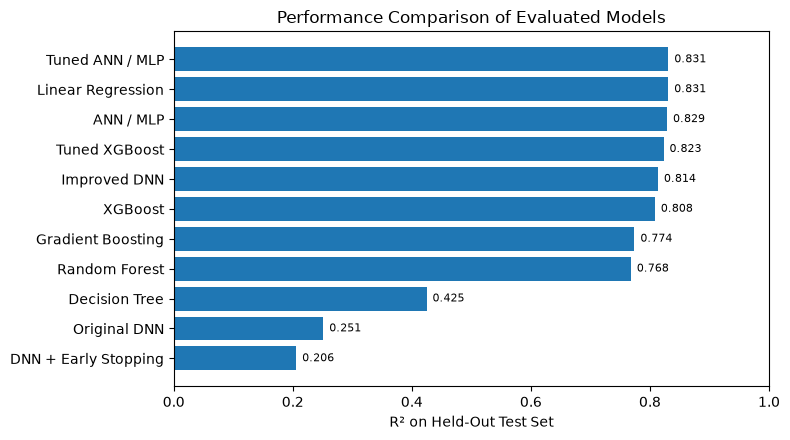

In [110]:
# Sort models so the lowest R² appears at the bottom.
plot_df = results_df.sort_values("R2", ascending=True)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.barh(
    plot_df["Model"],
    plot_df["R2"]
)

ax.set_xlabel("R² on Held-Out Test Set")
ax.set_title("Performance Comparison of Evaluated Models")
ax.set_xlim(0, 1)

# Display the value next to each bar.
for position, value in enumerate(plot_df["R2"]):
    ax.text(
        value + 0.01,
        position,
        f"{value:.3f}",
        va="center",
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    "model_comparison_r2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

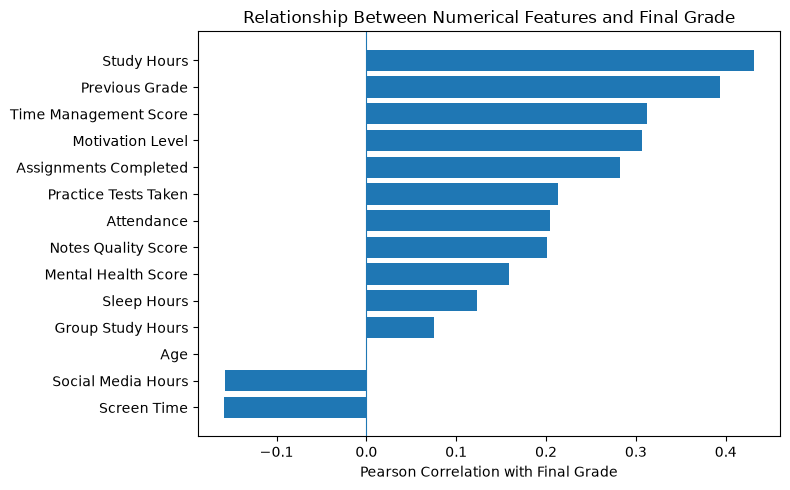

In [111]:
# Calculate correlations with the target variable.
correlations = (
    df.select_dtypes(include=np.number)
    .corr()["final_grade"]
    .drop("final_grade")
    .sort_values()
)

# Format feature names for readability.
labels = [
    feature.replace("_", " ").title()
    for feature in correlations.index
]

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    labels,
    correlations.values
)

ax.axvline(0, linewidth=0.8)

ax.set_xlabel("Pearson Correlation with Final Grade")
ax.set_title("Relationship Between Numerical Features and Final Grade")

plt.tight_layout()

plt.savefig(
    "correlation_with_final_grade.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()